# [16.15] Expected Gradients: Which Expectation Does GradientSHAP Estimate?

> **Claim.** Expected Gradients can converge to a complete continuous-path attribution while
> disagreeing with exact Shapley values for the same finite background. Gaussian query noise changes
> the prediction target as well as the estimator.

## Core Question

Which expectation does a GradientSHAP implementation estimate, and how can we distinguish Monte
Carlo error from a different attribution target?

Start with the smallest useful example:

$$
f(z)=\operatorname{ReLU}(z),\qquad x=1,\qquad b=-1.
$$

At a uniformly sampled point $b+\alpha(x-b)$, the path contribution is

$$
C(\alpha)=(x-b)f'(b+\alpha(x-b))=
\begin{cases}
0,&\alpha<\tfrac12,\\
2,&\alpha>\tfrac12.
\end{cases}
$$

Thus one draw is a Bernoulli-valued estimate, even though the population attribution is exactly
$E[C]=1$. Its variance is 1 and the ordinary standard error of a $K$-draw mean is $1/\sqrt K$.
A finite explanation need not sum exactly to $f(x)-f(b)=1$; that residual is sampling error.

You will build this estimator from explicit donor and path schedules, then compare it with numerical
quadrature and exhaustive feature-coalition Shapley. The real study uses every held-out concrete
recipe and the same seven raw-MPa models as section 16.14. It runs on CPU in float64. Allow
**4–6 hours**; Exercises 3–7 contain the core gradient, estimator and integration logic.

## Learning objectives

By the end of the lab, you should be able to:

- derive Integrated Gradients and Expected Gradients from a straight-line path;
- create row-stable, prefix-stable donor and alpha schedules without mutating global RNG state;
- retain individual gradient-times-displacement samples before averaging them;
- compute the ordinary plug-in Monte Carlo standard error from an unbiased sample-variance
  estimate, and explain what it does and does not measure;
- distinguish a full-background base from the sampled-donor average in one finite run;
- use all-background Gauss-Legendre quadrature as an approximate numerical control;
- prove that a complete path allocation can differ from discrete feature Shapley;
- explain why Gaussian query noise changes the target to a smoothed prediction;
- use global explanation-split rankings for audit replacement curves and local rankings only for
  exploratory plays.

## Setup

The student implementation supports deterministic scalar-output PyTorch models that act
independently on each row. Tensors and model parameters use CPU float64. Explicit schedules make
sampling semantics reviewable and allow smaller budgets to be literal prefixes of larger ones.


In [1]:
import hashlib
import math
import os
import sys
from collections.abc import Mapping, Sequence
from pathlib import Path
from types import SimpleNamespace
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch as t
from IPython.display import display
from torch import Tensor, nn

torch.set_default_dtype(torch.float64)

chapter = "chapter16_shapley_attribution_baselines"
section = "part15_gradientshap"
root_dir = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

from part15_gradientshap import gradientshap_methods_tests as tests
from part15_gradientshap import gradientshap_plots as plots
from part15_gradientshap.gradientshap_data import (
    background_order,
    load_manifest,
    load_split,
    tensor_mapping_sha256,
)

FEATURE_NAMES = np.array([
    "Cement", "Slag", "Fly ash", "Water", "Superplasticizer",
    "Coarse aggregate", "Fine aggregate", "Age",
])
RUN_OUTPUT = os.environ.get("ARENA_GRADIENTSHAP_OUTPUT_DIRECTORY")
FIGURE_DIR = Path(
    os.environ.get("ARENA_GRADIENTSHAP_FIGURE_DIR", RUN_OUTPUT or section_dir / "figures")
)
SAVE_FIGURES = os.environ.get(
    "ARENA_GRADIENTSHAP_SAVE_FIGURES", "1" if RUN_OUTPUT else "0"
) == "1"


def show_figure(fig, stem):
    """Display a figure and optionally save the exact notebook rendering."""
    display(fig)
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


The named helpers below are mechanical tensor, model, schedule, and state validators. They check
the lesson's declared boundary but do not implement any attribution operation. Every Expected
Gradients method remains in the exercises.


In [2]:
from part15_gradientshap.gradientshap_methods import (
    _eg_float_tensor,
    _eg_index_tensor,
    _eg_model,
    _eg_model_output,
    _eg_positive_int,
    _eg_preserve_execution_state,
    _eg_seed_words,
    _eg_validate_paths,
)


Diagnostic fixtures construct literal affine, quadratic, ReLU and constant functions. Each staged
check resolves only methods already defined above it.


In [3]:
DTYPE = t.float64

def _method(methods, name):
    if methods is None:
        from . import gradientshap_methods

        candidate = getattr(gradientshap_methods, name)
    elif isinstance(methods, Mapping):
        candidate = methods.get(name)
    else:
        candidate = getattr(methods, name, None)
    if not callable(candidate):
        raise TypeError(
            f"Learner method namespace must provide a callable {name!r}; "
            "pass globals(), a mapping, or a SimpleNamespace built from the taught methods."
        )
    return candidate

def _linear(weight, bias):
    weight = t.as_tensor(weight, dtype=DTYPE)
    bias = t.as_tensor(bias, dtype=DTYPE).reshape(-1)
    layer = nn.Linear(weight.shape[1], weight.shape[0], dtype=DTYPE)
    with t.no_grad():
        layer.weight.copy_(weight)
        layer.bias.copy_(bias)
    return layer

def _prediction(model, rows):
    with t.no_grad():
        return model(rows).reshape(-1)

def _max_abs(left, right):
    left = t.as_tensor(left, dtype=DTYPE)
    right = t.as_tensor(right, dtype=DTYPE)
    return float((left - right).abs().max())

def _relu_model():
    return nn.Sequential(_linear([[1.0]], [0.0]), nn.ReLU()).eval()

def _threshold_model(weights=(2.0, 1.0), bias=-2.0):
    weights = t.as_tensor(weights, dtype=DTYPE).reshape(1, -1)
    return nn.Sequential(_linear(weights, [bias]), nn.ReLU()).eval()

def _quadratic_model():
    class Quadratic(nn.Module):
        def forward(self, rows):
            return rows[:, 0].square()

    return Quadratic().eval()

def _two_feature_shapley(values):
    values = t.as_tensor(values, dtype=DTYPE).reshape(4)
    phi_0 = ((values[1] - values[0]) + (values[3] - values[2])) / 2
    phi_1 = ((values[2] - values[0]) + (values[3] - values[1])) / 2
    return t.stack((phi_0, phi_1))


## From Integrated Gradients to an expectation

For a differentiable scalar function $f:\mathbb R^D\to\mathbb R$, query $x$, and fixed baseline
$b$, straight-line Integrated Gradients is

$$
\operatorname{IG}_i(x;b)
=(x_i-b_i)\int_0^1
\frac{\partial f\bigl(b+\alpha(x-b)\bigr)}{\partial x_i}\,d\alpha.
$$

If the line-restricted function is absolutely continuous, the chain rule and fundamental theorem of
calculus give

$$
\begin{aligned}
f(x)-f(b)
&=\int_0^1 \frac{d}{d\alpha}f\bigl(b+\alpha(x-b)\bigr)\,d\alpha\\
&=\sum_i (x_i-b_i)\int_0^1
\partial_i f\bigl(b+\alpha(x-b)\bigr)\,d\alpha\\
&=\sum_i \operatorname{IG}_i(x;b).
\end{aligned}
$$

Expected Gradients also samples the baseline $B$:

$$
\operatorname{EG}_i(x;P_B)
=\mathbb E_{b\sim P_B,\,\alpha\sim U(0,1)}
\left[(x_i-b_i)\partial_i f\bigl(b+\alpha(x-b)\bigr)\right].
$$

For this lesson, $P_B$ is uniform over declared intact background rows. The expectation therefore
sums to $f(x)-\mathbb E_b[f(b)]$ under the same path regularity assumptions. A finite sample mean is
unbiased for this quantity, but it is not exactly complete draw by draw.

## 1️⃣ Build a reproducible path schedule

A schedule contains a donor index and one uniform $\alpha$ for every source row and draw. The
important invariant is stronger than ordinary seeded reproducibility: each source ID owns
independent donor and alpha streams. Therefore changing row order, row batching, or the maximum
budget does not change an existing row's prefix.

A single generator that first draws an `(N,K)` donor array and then an `(N,K)` alpha array violates
this invariant. Increasing `K` advances the generator farther before any alpha is drawn, so even the
old alpha prefix changes.

### Exercise 1 — `sample_path_schedule`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20-30 minutes on this exercise.
> ```

Return CPU arrays `indices` and `alpha`, each with shape `(N,K)`. Donor indices are int64 in
`[0, background_rows)`; alphas are float64 in `[0,1)`. Derive separate local streams from the fixed
seed, source ID, and stream name. Never alter NumPy's global RNG.


In [4]:
def sample_path_schedule(
    source_ids: Tensor,
    background_rows: int,
    samples: int,
    seed: int,
) -> tuple[Tensor, Tensor]:
    """Draw donor indices and alphas from independent local streams for each source ID."""
    _eg_index_tensor("source_ids", source_ids, 1)
    background_rows = _eg_positive_int("background_rows", background_rows)
    samples = _eg_positive_int("samples", samples)
    if type(seed) is not int or seed < 0 or seed >= 2**64:
        raise ValueError("seed must be an integer in [0, 2**64).")
    if (source_ids < 0).any():
        raise ValueError("source_ids must be nonnegative integers.")
    if len(t.unique(source_ids)) != len(source_ids):
        raise ValueError("source_ids must be unique so every row names one sampling stream.")

    indices = np.empty((len(source_ids), samples), dtype=np.int64)
    alpha = np.empty((len(source_ids), samples), dtype=np.float64)
    for row, source_id in enumerate(source_ids.tolist()):
        donor_rng = np.random.Generator(
            np.random.PCG64(_eg_seed_words(seed, source_id, "baseline"))
        )
        alpha_rng = np.random.Generator(
            np.random.PCG64(_eg_seed_words(seed, source_id, "alpha"))
        )
        indices[row] = donor_rng.integers(0, background_rows, size=samples, dtype=np.int64)
        alpha[row] = alpha_rng.random(samples, dtype=np.float64)
    return t.tensor(indices, dtype=t.int64), t.tensor(alpha, dtype=t.float64)



tests.test_sample_path_schedule(sample_path_schedule)


All tests in test_sample_path_schedule passed!


<details><summary>Help - give each source two private streams</summary>

Validate the source IDs first. For each ID, derive one deterministic seed for donors and another for
alphas, create local `np.random.Generator` instances, and draw length `samples` vectors. Do not use
Python's salted `hash` or the legacy global `np.random` functions.

</details>

<details><summary>Common bug - one generator for the whole batch</summary>

A batch-level generator can reproduce one exact call while failing the scientific invariant. Check
the same source ID after reordering the rows, after requesting more draws, and by itself. Its donor
and alpha prefixes must be identical in all four calls.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_sample_path_schedule passed!
```

The diagnostic prints fixed donor IDs and alphas, then confirms that the first eight draws are the
literal prefix of a 32-draw schedule.

</details>

<details><summary>Interpretation</summary>

A schedule is part of the estimator definition, not incidental randomness. Prefix stability lets a
convergence plot compare budgets on paired draws rather than silently changing every earlier draw.
Row-stable streams also make batching an implementation detail instead of a scientific choice.

</details>

<details><summary>Solution</summary>

```python
def sample_path_schedule(
    source_ids: Tensor,
    background_rows: int,
    samples: int,
    seed: int,
) -> tuple[Tensor, Tensor]:
    """Draw donor indices and alphas from independent local streams for each source ID."""
    _eg_index_tensor("source_ids", source_ids, 1)
    background_rows = _eg_positive_int("background_rows", background_rows)
    samples = _eg_positive_int("samples", samples)
    if type(seed) is not int or seed < 0 or seed >= 2**64:
        raise ValueError("seed must be an integer in [0, 2**64).")
    if (source_ids < 0).any():
        raise ValueError("source_ids must be nonnegative integers.")
    if len(t.unique(source_ids)) != len(source_ids):
        raise ValueError("source_ids must be unique so every row names one sampling stream.")

    indices = np.empty((len(source_ids), samples), dtype=np.int64)
    alpha = np.empty((len(source_ids), samples), dtype=np.float64)
    for row, source_id in enumerate(source_ids.tolist()):
        donor_rng = np.random.Generator(
            np.random.PCG64(_eg_seed_words(seed, source_id, "baseline"))
        )
        alpha_rng = np.random.Generator(
            np.random.PCG64(_eg_seed_words(seed, source_id, "alpha"))
        )
        indices[row] = donor_rng.integers(0, background_rows, size=samples, dtype=np.int64)
        alpha[row] = alpha_rng.random(samples, dtype=np.float64)
    return t.tensor(indices, dtype=t.int64), t.tensor(alpha, dtype=t.float64)
```

</details>


In [5]:
def schedule_fixture():
    return {
        "source_ids": t.tensor([101, 305, 909], dtype=t.int64),
        "background_rows": 5,
        "short_samples": 8,
        "long_samples": 32,
        "seed": 161510,
    }


In [6]:
def diagnose_schedule(sample_path_schedule_fn):
    fixture = schedule_fixture()
    source_ids = fixture["source_ids"]
    args = (fixture["background_rows"], fixture["seed"])
    indices_8, alpha_8 = sample_path_schedule_fn(
        source_ids, args[0], fixture["short_samples"], args[1]
    )
    indices_32, alpha_32 = sample_path_schedule_fn(
        source_ids, args[0], fixture["long_samples"], args[1]
    )
    reordered = source_ids[t.tensor([2, 0], dtype=t.int64)]
    reorder_indices, reorder_alpha = sample_path_schedule_fn(
        reordered, args[0], fixture["short_samples"], args[1]
    )
    single_indices, single_alpha = sample_path_schedule_fn(
        source_ids[:1], args[0], fixture["short_samples"], args[1]
    )
    return {
        **fixture,
        "indices_8": indices_8,
        "alpha_8": alpha_8,
        "indices_32": indices_32,
        "alpha_32": alpha_32,
        "prefix_match": bool(
            t.equal(indices_8, indices_32[:, :8]) and t.equal(alpha_8, alpha_32[:, :8])
        ),
        "reorder_match": bool(
            t.equal(reorder_indices, indices_8[[2, 0]])
            and t.equal(reorder_alpha, alpha_8[[2, 0]])
        ),
        "single_row_match": bool(
            t.equal(single_indices, indices_8[:1]) and t.equal(single_alpha, alpha_8[:1])
        ),
    }


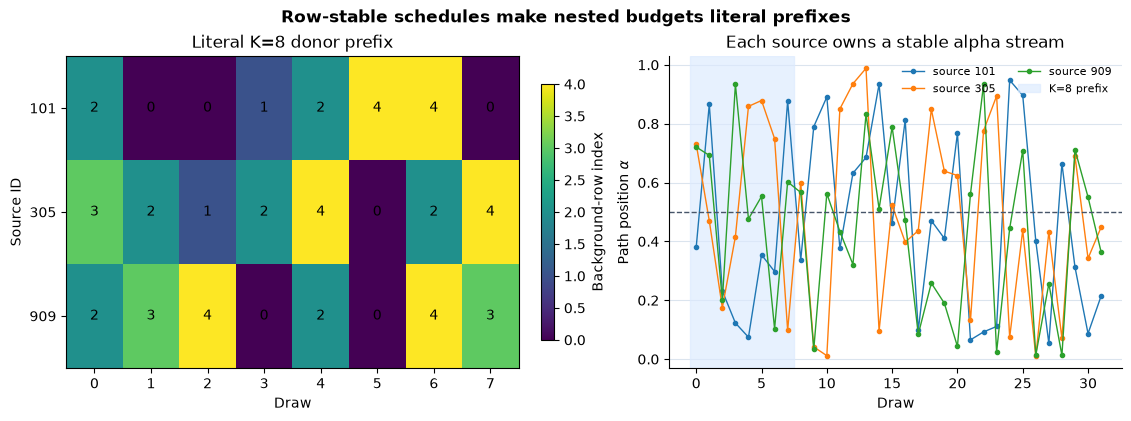

In [7]:
schedule_check = diagnose_schedule(sample_path_schedule)
show_figure(plots.plot_schedule_prefix(schedule_check), "01_schedule_prefix")


## 2️⃣ Interpolate both the point and displacement

For donor $b_k$, path position $\alpha_k$, and optional query perturbation $\epsilon_k$, define

$$
\tilde x_k=x+\epsilon_k,\qquad
p_k=b_k+\alpha_k(\tilde x_k-b_k),\qquad
\Delta_k=\tilde x_k-b_k.
$$

The gradient is evaluated at $p_k$ and multiplied by the same $\Delta_k$. Noise must appear in both
expressions. Perturbing the point while retaining the clean displacement computes a hybrid quantity
that is not the noisy Expected Gradients target.

### Exercise 2 — `interpolate_paths`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 15-20 minutes on this exercise.
> ```

Gather donors using `indices`, broadcast each query across its draw axis, and return `(points,
deltas)` with shape `(N,K,D)`. With `noise=None`, use an exact zero perturbation without drawing any
random numbers.


In [8]:
def interpolate_paths(
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    noise: Tensor | None = None,
) -> tuple[Tensor, Tensor]:
    """Return sampled path points and query-minus-donor deltas, both shaped N,K,D."""
    _eg_validate_paths(x, background, indices, alpha, noise)
    donors = background[indices]
    query = x[:, None, :] if noise is None else x[:, None, :] + noise
    delta = query - donors
    points = donors + alpha[:, :, None] * delta
    return points, delta



tests.test_interpolate_paths(interpolate_paths)


All tests in test_interpolate_paths passed!


<details><summary>Help - name the three broadcast axes</summary>

`x[:, None, :]` is `(N,1,D)`, `background[indices]` is `(N,K,D)`, and
`alpha[:, :, None]` is `(N,K,1)`. Build the noisy query first; use that same tensor in both the
convex combination and subtraction.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_interpolate_paths passed!
```

For $f(z)=z^2$, $x=1$, $b=0$, and alphas `(0.25,0.75)`, the points are `(0.25,0.75)` and both
displacements are one.

</details>

<details><summary>Interpretation</summary>

The path position controls where the model is differentiated; the displacement controls how that
local sensitivity is converted into a finite input contribution. Keeping these arrays separate
makes a missing-noise or wrong-donor bug visible before autograd is involved.

</details>

<details><summary>Solution</summary>

```python
def interpolate_paths(
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    noise: Tensor | None = None,
) -> tuple[Tensor, Tensor]:
    """Return sampled path points and query-minus-donor deltas, both shaped N,K,D."""
    _eg_validate_paths(x, background, indices, alpha, noise)
    donors = background[indices]
    query = x[:, None, :] if noise is None else x[:, None, :] + noise
    delta = query - donors
    points = donors + alpha[:, :, None] * delta
    return points, delta
```

</details>


In [9]:
def path_fixture():
    return {
        "query": t.tensor([[2.0, 1.0]], dtype=DTYPE),
        "background": t.tensor([[-1.0, 0.0], [0.0, 2.0]], dtype=DTYPE),
        "indices": t.tensor([[0, 1, 0, 1]], dtype=t.int64),
        "alpha": t.tensor([[0.20, 0.35, 0.75, 0.90]], dtype=DTYPE),
    }


In [10]:
def diagnose_interpolation(interpolate_paths_fn):
    fixture = path_fixture()
    points, deltas = interpolate_paths_fn(
        fixture["query"],
        fixture["background"],
        fixture["indices"],
        fixture["alpha"],
    )
    donors = fixture["background"][fixture["indices"]]
    expected = donors + fixture["alpha"][..., None] * (fixture["query"][:, None, :] - donors)
    return {
        **fixture,
        "donors": donors,
        "points": points,
        "deltas": deltas,
        "expected_points": expected,
        "max_abs_error": _max_abs(points, expected),
    }


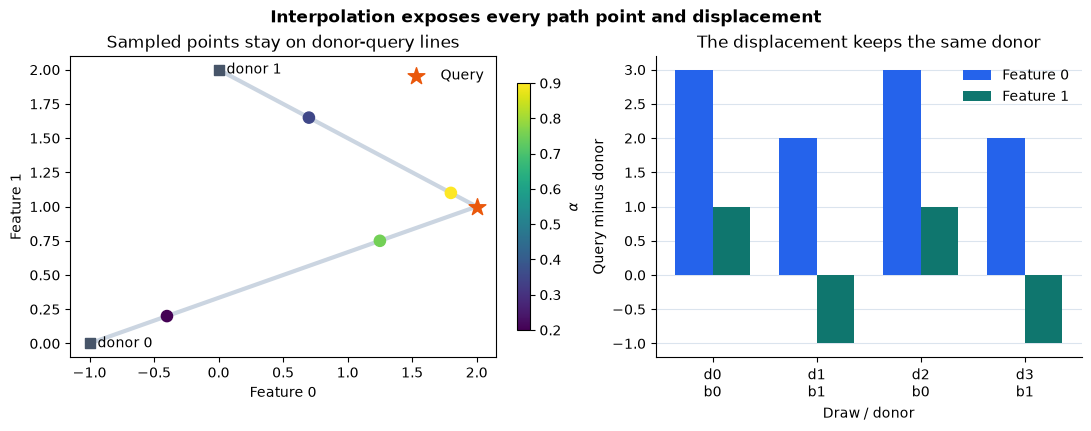

In [11]:
path_check = diagnose_interpolation(interpolate_paths)
show_figure(plots.plot_path_interpolation(path_check), "02_path_interpolation")


## 3️⃣ Differentiate a scalar row-wise model

Flattening `(N,K,D)` path points to `(N*K,D)` lets one backward call evaluate many samples. For a
model that applies the same scalar function independently to every row,

$$
\nabla_P\sum_r f(P_r)
=\bigl(\nabla f(P_1),\ldots,\nabla f(P_{NK})\bigr).
$$

The equality depends on row independence. Merely observing one scalar per row does not prove it for
a model with batch-dependent operations. This lesson validates a deliberately narrow graph before
using the sum-of-outputs trick.

The helper must also preserve the supported caller state: input storage, model training mode,
buffers, global RNG state, and any existing parameter gradients. The supported study models do not
mutate their parameter values during `forward`. The returned gradient is fresh CPU float64 storage.

### Exercise 3 — `input_gradients`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 30-40 minutes on this exercise.
> ```

Differentiate the model in bounded `forward_batch` chunks and restore its original mode. Do not use
`loss.backward()`, which accumulates parameter gradients. Use `torch.autograd.grad` with respect to
a fresh point tensor.


In [12]:
def input_gradients(
    model: nn.Module,
    points: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Differentiate a deterministic scalar function applied independently to each row.

    The sum-of-outputs gradient is valid only under that batch-independence assumption.
    This function preserves the caller's tensors, RNG states, model modes, buffers, and
    parameter gradients. A scalar function constant with respect to its input gets zero
    input gradients.
    """
    model = _eg_model(model)
    _eg_float_tensor("points", points, 3)
    forward_batch = _eg_positive_int("forward_batch", forward_batch)
    flat_points = points.reshape(-1, points.shape[-1])
    flat_gradients = t.empty_like(flat_points)

    with _eg_preserve_execution_state(model):
        for start in range(0, len(flat_points), forward_batch):
            chunk = flat_points[start : start + forward_batch].detach().clone().requires_grad_(True)
            with t.enable_grad():
                output = _eg_model_output(model, chunk)
                if output.requires_grad:
                    gradient = t.autograd.grad(output.sum(), chunk, allow_unused=True)[0]
                else:
                    gradient = None
            if gradient is None:
                gradient = t.zeros_like(chunk)
            if not t.isfinite(gradient).all():
                raise ValueError("The model produced a nonfinite input gradient.")
            flat_gradients[start : start + len(chunk)] = gradient.detach()
    return flat_gradients.reshape(points.shape)



tests.test_input_gradients(input_gradients)


All tests in test_input_gradients passed!


<details><summary>Help - differentiate only the temporary input</summary>

For each flattened chunk, use `detach().clone().requires_grad_(True)`. Evaluate a validated scalar
output, call `torch.autograd.grad(output.sum(), chunk)`, detach the result, and reshape the
concatenated gradients to the original point shape. Save and restore `model.training` in a
`try/finally` block.

</details>

<details><summary>Common bug - clearing parameter gradients</summary>

Calling `model.zero_grad()` avoids new accumulation but destroys gradients the caller may already
hold. `autograd.grad` can request only the input derivative, leaving every parameter's `.grad`
unchanged. Tests should seed nonzero parameter gradients before the call and compare them after it.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_input_gradients passed!
```

The affine gradient is constant, the quadratic gradient changes with the path point, and a constant
model returns the deliberate zero-gradient behavior specified by the method contract.

</details>

<details><summary>Interpretation</summary>

Expected Gradients is inexpensive because it replaces a path integral by sampled ordinary input
gradients. That computational shortcut is valid only if each flattened row means the same function
call it meant before batching.

</details>

<details><summary>Solution</summary>

```python
def input_gradients(
    model: nn.Module,
    points: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Differentiate a deterministic scalar function applied independently to each row.

    The sum-of-outputs gradient is valid only under that batch-independence assumption.
    This function preserves the caller's tensors, RNG states, model modes, buffers, and
    parameter gradients. A scalar function constant with respect to its input gets zero
    input gradients.
    """
    model = _eg_model(model)
    _eg_float_tensor("points", points, 3)
    forward_batch = _eg_positive_int("forward_batch", forward_batch)
    flat_points = points.reshape(-1, points.shape[-1])
    flat_gradients = t.empty_like(flat_points)

    with _eg_preserve_execution_state(model):
        for start in range(0, len(flat_points), forward_batch):
            chunk = flat_points[start : start + forward_batch].detach().clone().requires_grad_(True)
            with t.enable_grad():
                output = _eg_model_output(model, chunk)
                if output.requires_grad:
                    gradient = t.autograd.grad(output.sum(), chunk, allow_unused=True)[0]
                else:
                    gradient = None
            if gradient is None:
                gradient = t.zeros_like(chunk)
            if not t.isfinite(gradient).all():
                raise ValueError("The model produced a nonfinite input gradient.")
            flat_gradients[start : start + len(chunk)] = gradient.detach()
    return flat_gradients.reshape(points.shape)
```

</details>


In [13]:
def gradient_fixture():
    affine = nn.Sequential(_linear([[2.0, -3.0]], [0.5])).eval()
    affine_points = t.tensor(
        [[[-1.0, 0.0], [0.5, 2.0], [2.0, -1.0], [3.0, 3.0]]],
        dtype=DTYPE,
    )
    z = t.linspace(-1.0, 1.5, 21, dtype=DTYPE)
    return {
        "affine_model": affine,
        "affine_points": affine_points,
        "affine_expected": t.tensor([2.0, -3.0], dtype=DTYPE),
        "quadratic_model": _quadratic_model(),
        "quadratic_points": z.reshape(1, -1, 1),
        "quadratic_expected": (2 * z).reshape(1, -1, 1),
    }


In [14]:
def diagnose_gradients(input_gradients_fn):
    fixture = gradient_fixture()
    affine = input_gradients_fn(fixture["affine_model"], fixture["affine_points"])
    quadratic = input_gradients_fn(fixture["quadratic_model"], fixture["quadratic_points"])
    return {
        "affine_points": fixture["affine_points"],
        "affine_gradients": affine,
        "affine_expected": fixture["affine_expected"],
        "affine_max_abs_error": _max_abs(affine, fixture["affine_expected"]),
        "quadratic_points": fixture["quadratic_points"],
        "quadratic_gradients": quadratic,
        "quadratic_expected": fixture["quadratic_expected"],
        "quadratic_max_abs_error": _max_abs(quadratic, fixture["quadratic_expected"]),
    }


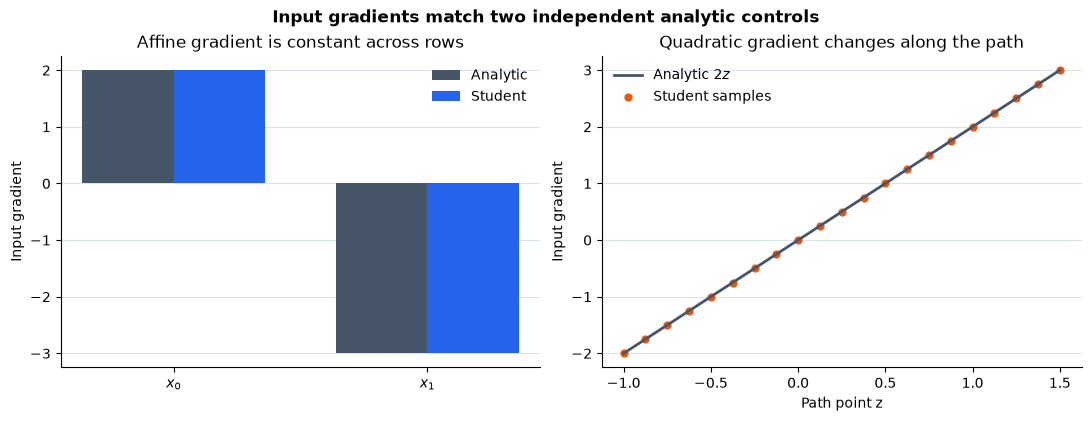

In [15]:
gradient_check = diagnose_gradients(input_gradients)
show_figure(plots.plot_gradient_controls(gradient_check), "03_gradient_controls")


## 4️⃣ Retain every Expected Gradients draw

For explicit schedule entries $(j_{nk},\alpha_{nk})$, choose donor
$b_{nk}=B_{j_{nk}}$, form $p_{nk}=b_{nk}+\alpha_{nk}(x_n-b_{nk})$, and retain

$$
C_{nki}=(x_{ni}-b_{nki})\partial_i f(p_{nk}).
$$

The estimator is the draw mean, but averaging here would throw away the evidence needed to measure
Monte Carlo uncertainty, inspect discrete samples, and reuse literal prefixes. This function returns
the full `(N,K,D)` contribution tensor.

For the opening ReLU, alphas `(0.25,0.75)` produce path points `(-0.5,0.5)`, gradients `(0,1)`,
and contributions `(0,2)`. For $f(z)=z^2$, $x=1$, $b=0$, the same alphas produce contributions
`(0.5,1.5)`. An endpoint-gradient implementation would return two in both quadratic draws and fail.

### Exercise 4 — `expected_gradient_samples`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20-30 minutes on this exercise.
> ```

Compose `interpolate_paths` and `input_gradients`, then multiply gradients by displacements. Preserve
all draws and return fresh storage.


In [16]:
def expected_gradient_samples(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Return clean Expected Gradients Monte Carlo contributions, shape N,K,D."""
    points, delta = interpolate_paths(x, background, indices, alpha)
    gradients = input_gradients(model, points, forward_batch)
    return gradients * delta



tests.test_expected_gradient_samples(expected_gradient_samples)


All tests in test_expected_gradient_samples passed!


<details><summary>Help - the method is a three-line composition</summary>

Call `interpolate_paths(x, background, indices, alpha)`, pass the points to `input_gradients`, and
multiply by the returned deltas. Most of the work is in preserving shapes and state in the two
functions you already wrote.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_expected_gradient_samples passed!
```

The diagnostic displays literal ReLU samples `(0,2)` and quadratic samples `(0.5,1.5)` on their
analytic distributions.

</details>

<details><summary>Interpretation</summary>

A contribution draw combines two random choices: which endpoint donor defines the path and where
the gradient is sampled on that path. Retaining draws lets us quantify their combined estimator
variation. It does not quantify uncertainty about the trained model, dataset, or choice of baseline
distribution.

</details>

<details><summary>Solution</summary>

```python
def expected_gradient_samples(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Return clean Expected Gradients Monte Carlo contributions, shape N,K,D."""
    points, delta = interpolate_paths(x, background, indices, alpha)
    gradients = input_gradients(model, points, forward_batch)
    return gradients * delta
```

</details>


In [17]:
def sample_fixture():
    return {
        "relu_model": _relu_model(),
        "relu_query": t.tensor([[1.0]], dtype=DTYPE),
        "relu_background": t.tensor([[-1.0]], dtype=DTYPE),
        "source_ids": t.tensor([17], dtype=t.int64),
        "samples": 128,
        "seed": 161510,
        "quadratic_model": _quadratic_model(),
        "quadratic_query": t.tensor([[1.0]], dtype=DTYPE),
        "quadratic_background": t.tensor([[0.0]], dtype=DTYPE),
        "quadratic_indices": t.tensor([[0, 0]], dtype=t.int64),
        "quadratic_alpha": t.tensor([[0.25, 0.75]], dtype=DTYPE),
    }


In [18]:
def diagnose_expected_gradient_samples(
    expected_gradient_samples_fn,
    sample_path_schedule_fn,
):
    fixture = sample_fixture()
    indices, alpha = sample_path_schedule_fn(
        fixture["source_ids"], 1, fixture["samples"], fixture["seed"]
    )
    relu_samples = expected_gradient_samples_fn(
        fixture["relu_model"],
        fixture["relu_query"],
        fixture["relu_background"],
        indices,
        alpha,
    )
    quadratic_samples = expected_gradient_samples_fn(
        fixture["quadratic_model"],
        fixture["quadratic_query"],
        fixture["quadratic_background"],
        fixture["quadratic_indices"],
        fixture["quadratic_alpha"],
    )
    relu_expected = (alpha > 0.5).to(DTYPE)[..., None] * 2.0
    quadratic_expected = (2 * fixture["quadratic_alpha"])[..., None]
    return {
        "alpha": alpha,
        "relu_samples": relu_samples,
        "relu_expected": relu_expected,
        "relu_max_abs_error": _max_abs(relu_samples, relu_expected),
        "quadratic_alpha": fixture["quadratic_alpha"],
        "quadratic_samples": quadratic_samples,
        "quadratic_expected": quadratic_expected,
        "quadratic_max_abs_error": _max_abs(quadratic_samples, quadratic_expected),
        "population_mean": t.tensor(1.0, dtype=DTYPE),
        "population_variance": t.tensor(1.0, dtype=DTYPE),
    }


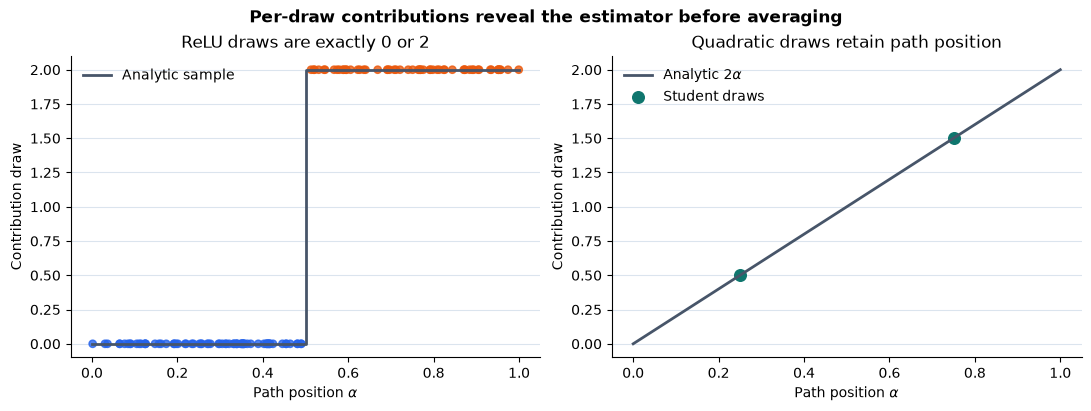

In [19]:
sample_check = diagnose_expected_gradient_samples(
    expected_gradient_samples,
    sample_path_schedule,
)
show_figure(plots.plot_relu_samples(sample_check), "04_relu_samples")


## 5️⃣ Estimate a mean and its Monte Carlo standard error

For one feature coordinate with draws $C_1,\ldots,C_K$, define

$$
\widehat\phi_K=\frac1K\sum_{k=1}^K C_k,
\qquad
s_K^2=\frac1{K-1}\sum_{k=1}^K(C_k-\widehat\phi_K)^2,
\qquad
\widehat{\operatorname{SE}}_K=\frac{s_K}{\sqrt K}.
$$

The `K-1` denominator makes $s_K^2$ the unbiased sample-variance estimator. The standard error
estimates variability of the sample mean under repeated schedules. It is not a standard deviation of
feature importance, a model confidence interval, or a bound on error against exact coalition
Shapley. Coordinates also share donor and alpha draws, so their errors are correlated.

Nested budgets use literal prefixes of the same contribution tensor. That pairing makes a running
plot interpretable: only additional draws change the estimate.

### Exercise 5 — `summarize_expected_gradients`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20-30 minutes on this exercise.
> ```

For every requested budget, return the prefix mean and ordinary standard error. Validate increasing,
unique budgets that fit inside the draw axis. Do not use SHAP's package-reported uncertainty field;
we will inspect its different formula later.


In [20]:
def summarize_expected_gradients(
    samples: Tensor,
    budgets: tuple[int, ...],
) -> tuple[Tensor, Tensor]:
    """Return ordinary sample SE, not SHAP 0.49.1's variance/sqrt(K) proxy."""
    _eg_float_tensor("samples", samples, 3)
    if type(budgets) is not tuple or not budgets:
        raise TypeError("budgets must be a nonempty tuple of sample counts.")
    if any(type(budget) is not int for budget in budgets):
        raise TypeError("Every budget must be an integer sample count.")
    if any(budget < 2 or budget > samples.shape[1] for budget in budgets):
        raise ValueError("Every budget must be between 2 and the available sample count.")
    if any(left >= right for left, right in zip(budgets, budgets[1:])):
        raise ValueError("budgets must be strictly increasing nested prefixes.")

    means, standard_errors = [], []
    for budget in budgets:
        prefix = samples[:, :budget]
        means.append(prefix.mean(dim=1))
        standard_errors.append(prefix.std(dim=1, correction=1) / math.sqrt(budget))
    return t.stack(means), t.stack(standard_errors)



tests.test_summarize_expected_gradients(summarize_expected_gradients)


All tests in test_summarize_expected_gradients passed!


<details><summary>Help - slice first, then reduce the draw axis</summary>

For each `budget`, select `samples[:, :budget]`. Compute its mean over dimension 1 and its sample
standard deviation with `correction=1`, then divide by `sqrt(budget)`. Stack results in budget order;
do not reduce the query or feature dimensions.

</details>

<details><summary>Common bug - calling sample spread an estimator SE</summary>

`prefix.std(dim=1)` measures the spread of individual contributions. The uncertainty of their mean
is smaller by `sqrt(K)`. Conversely, dividing the variance itself by `sqrt(K)` is neither the
ordinary variance of the mean nor its standard error.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_summarize_expected_gradients passed!
```

For the analytic ReLU distribution, independent repetitions should shrink like $1/\sqrt K$ while
individual draws remain zero or two.

</details>

<details><summary>Interpretation</summary>

A smaller reported SE says the declared Monte Carlo mean is becoming stable for this estimand. It
does not say the baseline distribution is appropriate, that the path stays on the data manifold, or
that Expected Gradients agrees with discrete Shapley.

</details>

<details><summary>Solution</summary>

```python
def summarize_expected_gradients(
    samples: Tensor,
    budgets: tuple[int, ...],
) -> tuple[Tensor, Tensor]:
    """Return ordinary sample SE, not SHAP 0.49.1's variance/sqrt(K) proxy."""
    _eg_float_tensor("samples", samples, 3)
    if type(budgets) is not tuple or not budgets:
        raise TypeError("budgets must be a nonempty tuple of sample counts.")
    if any(type(budget) is not int for budget in budgets):
        raise TypeError("Every budget must be an integer sample count.")
    if any(budget < 2 or budget > samples.shape[1] for budget in budgets):
        raise ValueError("Every budget must be between 2 and the available sample count.")
    if any(left >= right for left, right in zip(budgets, budgets[1:])):
        raise ValueError("budgets must be strictly increasing nested prefixes.")

    means, standard_errors = [], []
    for budget in budgets:
        prefix = samples[:, :budget]
        means.append(prefix.mean(dim=1))
        standard_errors.append(prefix.std(dim=1, correction=1) / math.sqrt(budget))
    return t.stack(means), t.stack(standard_errors)
```

</details>


In [21]:
def diagnose_convergence(
    sample_path_schedule_fn,
    expected_gradient_samples_fn,
    summarize_expected_gradients_fn,
):
    fixture = sample_fixture()
    indices, alpha = sample_path_schedule_fn(
        fixture["source_ids"], 1, fixture["samples"], fixture["seed"]
    )
    samples = expected_gradient_samples_fn(
        fixture["relu_model"],
        fixture["relu_query"],
        fixture["relu_background"],
        indices,
        alpha,
    )
    budgets = (2, 4, 8, 16, 32, 64, 128)
    means, standard_errors = summarize_expected_gradients_fn(samples, budgets)
    budget_tensor = t.tensor(budgets, dtype=DTYPE)
    return {
        "budgets": t.tensor(budgets, dtype=t.int64),
        "means": means[:, 0, 0],
        "standard_errors": standard_errors[:, 0, 0],
        "population_mean": t.tensor(1.0, dtype=DTYPE),
        "analytic_standard_error": budget_tensor.rsqrt(),
        "absolute_error": (means[:, 0, 0] - 1.0).abs(),
        "samples": samples,
    }


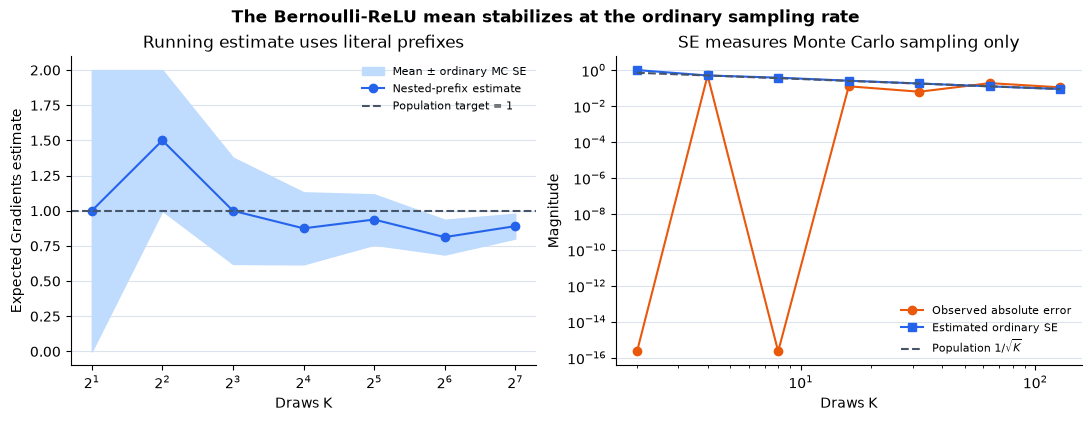

In [22]:
convergence_check = diagnose_convergence(
    sample_path_schedule,
    expected_gradient_samples,
    summarize_expected_gradients,
)
show_figure(plots.plot_mc_convergence(convergence_check), "05_mc_convergence")


The running estimate should wander between the two possible ReLU contributions before stabilizing
near one. The band is labeled **ordinary Monte Carlo SE** because that is the only uncertainty it
represents. Erion et al. found 100–200 samples adequate on their benchmarks; that empirical result
is not a universal stopping rule for this model or dataset.


## 6️⃣ Report the finite estimate against its actual base

The finite empirical-background target is

$$
\phi_0(B)=\frac1{|B|}\sum_{b\in B}f(b),
\qquad
\phi_0(B)+\sum_i\operatorname{EG}_i(x;B)=f(x).
$$

`expected_gradients` reports the deterministic full-background base, the finite draw mean, and its
ordinary SE. The finite residual

$$
r_K=\phi_0(B)+\sum_i\widehat\phi_{K,i}-f(x)
$$

contains both donor-sampling and alpha-sampling error. Replacing the base by the sampled donors'
mean prediction can make one component disappear from a diagnostic while silently changing the
quantity being checked.

### Exercise 6 — `expected_gradients`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20-30 minutes on this exercise.
> ```

Compose your per-draw estimator, average the draw axis, compute the ordinary SE, and evaluate the
model on every supplied background row for the base. Return all declared fields without mutating the
inputs or the supported model execution state.


In [23]:
def expected_gradients(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    forward_batch: int = 32_768,
) -> tuple[Tensor, Tensor, Tensor]:
    """Return full-background base, clean Expected Gradients, and ordinary estimator SE."""
    _, samples, _ = _eg_validate_paths(x, background, indices, alpha)
    if samples < 2:
        raise ValueError(
            "Expected Gradients needs at least two samples to estimate standard error."
        )
    contributions = expected_gradient_samples(
        model, x, background, indices, alpha, forward_batch
    )
    means, standard_errors = summarize_expected_gradients(contributions, (samples,))
    model = _eg_model(model)
    with _eg_preserve_execution_state(model), t.no_grad():
        base = _eg_model_output(model, background).mean().detach().clone()
    return base, means[0], standard_errors[0]



tests.test_expected_gradients(expected_gradients)


All tests in test_expected_gradients passed!


<details><summary>Help - reuse samples and retain the deterministic base</summary>

Call `expected_gradient_samples`, then summarize its complete draw axis. Evaluate the model on all
background rows under `torch.no_grad()` and average scalar outputs. Keep the base separate from the
attribution and SE arrays.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_expected_gradients passed!
```

The affine fixture is exact under its balanced donor schedule. Dummy and constant coordinates stay
zero. The finite ReLU fixture exposes a nonzero residual when its alpha sample is unbalanced.

</details>

<details><summary>Interpretation</summary>

Completeness is an expectation statement. A finite residual consistent with sampling variability is
not automatically an implementation failure. An affine, balanced-donor control remains valuable
because it removes alpha variation and has a hand-derived target.

</details>

<details><summary>Solution</summary>

```python
def expected_gradients(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    forward_batch: int = 32_768,
) -> tuple[Tensor, Tensor, Tensor]:
    """Return full-background base, clean Expected Gradients, and ordinary estimator SE."""
    _, samples, _ = _eg_validate_paths(x, background, indices, alpha)
    if samples < 2:
        raise ValueError(
            "Expected Gradients needs at least two samples to estimate standard error."
        )
    contributions = expected_gradient_samples(
        model, x, background, indices, alpha, forward_batch
    )
    means, standard_errors = summarize_expected_gradients(contributions, (samples,))
    model = _eg_model(model)
    with _eg_preserve_execution_state(model), t.no_grad():
        base = _eg_model_output(model, background).mean().detach().clone()
    return base, means[0], standard_errors[0]
```

</details>


In [24]:
def estimator_fixture():
    affine = nn.Sequential(_linear([[2.0, -3.0]], [0.5])).eval()
    dummy = nn.Sequential(_linear([[2.0, -3.0, 0.0]], [0.5])).eval()
    constant = nn.Sequential(_linear([[0.0, 0.0]], [2.0])).eval()
    return {
        "affine_model": affine,
        "affine_query": t.tensor([[2.0, 1.0]], dtype=DTYPE),
        "affine_background": t.tensor([[0.0, 0.0], [1.0, 2.0]], dtype=DTYPE),
        "balanced_indices": t.tensor([[0, 1, 0, 1]], dtype=t.int64),
        "balanced_alpha": t.tensor([[0.15, 0.35, 0.65, 0.85]], dtype=DTYPE),
        "affine_expected_phi": t.tensor([[3.0, 0.0]], dtype=DTYPE),
        "dummy_model": dummy,
        "dummy_query": t.tensor([[2.0, 1.0, 9.0]], dtype=DTYPE),
        "dummy_background": t.tensor([[0.0, 0.0, -5.0], [1.0, 2.0, 7.0]], dtype=DTYPE),
        "constant_model": constant,
        "relu_model": _relu_model(),
        "relu_query": t.tensor([[1.0]], dtype=DTYPE),
        "relu_background": t.tensor([[-1.0]], dtype=DTYPE),
        "relu_indices": t.zeros((1, 5), dtype=t.int64),
        "relu_alpha": t.tensor([[0.10, 0.20, 0.30, 0.40, 0.60]], dtype=DTYPE),
    }


In [25]:
def diagnose_expected_gradients(expected_gradients_fn, sample_path_schedule_fn):
    fixture = estimator_fixture()
    affine_base, affine_phi, affine_se = expected_gradients_fn(
        fixture["affine_model"],
        fixture["affine_query"],
        fixture["affine_background"],
        fixture["balanced_indices"],
        fixture["balanced_alpha"],
    )
    scheduled_indices, scheduled_alpha = sample_path_schedule_fn(
        t.tensor([41], dtype=t.int64), 2, 32, 161510
    )
    dummy_base, dummy_phi, dummy_se = expected_gradients_fn(
        fixture["dummy_model"],
        fixture["dummy_query"],
        fixture["dummy_background"],
        scheduled_indices,
        scheduled_alpha,
    )
    constant_base, constant_phi, constant_se = expected_gradients_fn(
        fixture["constant_model"],
        fixture["affine_query"],
        fixture["affine_background"],
        scheduled_indices,
        scheduled_alpha,
    )
    relu_base, relu_phi, relu_se = expected_gradients_fn(
        fixture["relu_model"],
        fixture["relu_query"],
        fixture["relu_background"],
        fixture["relu_indices"],
        fixture["relu_alpha"],
    )

    def result(model, query, base, phi, se):
        prediction = _prediction(model, query)[0]
        return {
            "base": base,
            "phi": phi,
            "standard_error": se,
            "prediction": prediction,
            "reconstruction": base + phi.sum(),
            "residual": base + phi.sum() - prediction,
        }

    return {
        "affine": result(
            fixture["affine_model"],
            fixture["affine_query"],
            affine_base,
            affine_phi,
            affine_se,
        ),
        "dummy": result(
            fixture["dummy_model"],
            fixture["dummy_query"],
            dummy_base,
            dummy_phi,
            dummy_se,
        ),
        "constant": result(
            fixture["constant_model"],
            fixture["affine_query"],
            constant_base,
            constant_phi,
            constant_se,
        ),
        "finite_relu": result(
            fixture["relu_model"],
            fixture["relu_query"],
            relu_base,
            relu_phi,
            relu_se,
        ),
        "affine_expected_phi": fixture["affine_expected_phi"],
        "affine_max_abs_error": _max_abs(affine_phi, fixture["affine_expected_phi"]),
        "dummy_max_abs": float(dummy_phi[:, 2].abs().max()),
        "constant_max_abs": float(constant_phi.abs().max()),
    }


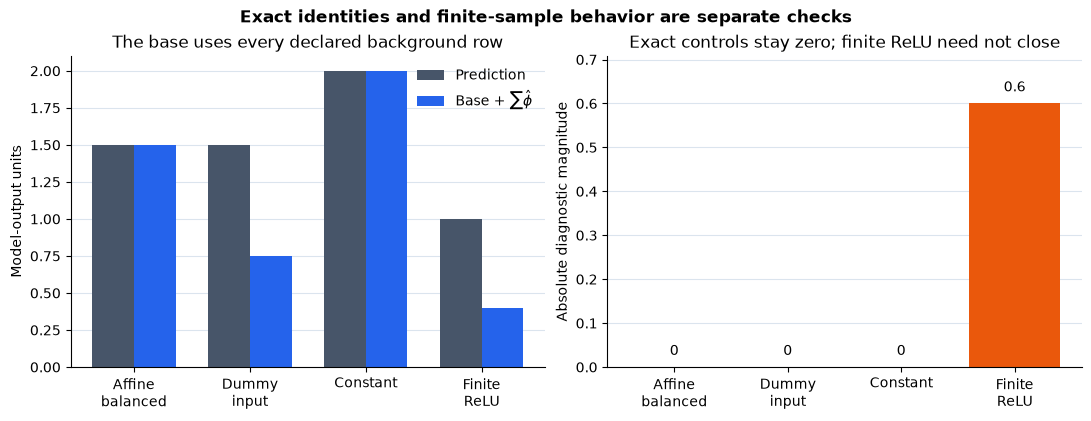

In [26]:
estimator_check = diagnose_expected_gradients(
    expected_gradients,
    sample_path_schedule,
)
show_figure(plots.plot_estimator_controls(estimator_check), "06_estimator_controls")


## 7️⃣ Replace random alpha draws with bounded quadrature

Monte Carlo sampling is the main estimator, but a deterministic alpha-integration control helps us
measure its error. Let $(q_\ell,w_\ell)$ be Gauss-Legendre nodes and weights on `[-1,1]`. Mapping

$$
\alpha_\ell=\frac{q_\ell+1}{2},\qquad \omega_\ell=\frac{w_\ell}{2}
$$

gives the pairwise approximation

$$
\widehat{\operatorname{IG}}_i(x;b)
=(x_i-b_i)\sum_{\ell=1}^{L}\omega_\ell
\partial_i f\bigl(b+\alpha_\ell(x-b)\bigr).
$$

Evaluate every query against every intact donor, returning `(N,B,D)` pair attributions. Averaging
that donor axis removes donor-sampling variation, while doubling the node count tests alpha
integration drift.

This remains numerical quadrature. A ReLU path has a step-discontinuous gradient at each kink, so
finite Gauss-Legendre integration is not an exact oracle. It is exact for the affine fixture and
should integrate the quadratic fixture to floating-point precision; for piecewise-linear networks,
report the 256-to-512-node change rather than declaring 512 exact.

### Exercise 7 — `gauss_legendre_pairs`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 35-50 minutes on this exercise.
> ```

Construct nodes with NumPy, map them to `[0,1]`, and evaluate all query/donor paths in bounded row
and forward batches. Multiply the weighted average gradient by each query-minus-donor displacement.


In [27]:
def gauss_legendre_pairs(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    n_nodes: int,
    row_batch: int = 4,
    forward_batch: int = 32_768,
) -> Tensor:
    """Approximate every query-donor Integrated Gradients path by finite quadrature.

    ReLU path gradients jump, so finite-node quadrature remains a numerical control
    rather than exact path truth.
    """
    model = _eg_model(model)
    _eg_float_tensor("x", x, 2)
    _eg_float_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    n_nodes = _eg_positive_int("n_nodes", n_nodes)
    row_batch = _eg_positive_int("row_batch", row_batch)
    forward_batch = _eg_positive_int("forward_batch", forward_batch)

    raw_nodes, raw_weights = np.polynomial.legendre.leggauss(n_nodes)
    nodes = t.tensor((raw_nodes + 1) / 2, dtype=t.float64)
    weights = t.tensor(raw_weights / 2, dtype=t.float64)
    pairs = t.empty((len(x), len(background), x.shape[1]), dtype=t.float64)

    for start in range(0, len(x), row_batch):
        query = x[start : start + row_batch]
        delta = query[:, None, :] - background[None, :, :]
        points = background[None, :, None, :] + nodes[None, None, :, None] * delta[:, :, None, :]
        packed = points.reshape(len(query), len(background) * n_nodes, x.shape[1])
        gradients = input_gradients(model, packed, forward_batch).reshape(points.shape)
        mean_gradient = (gradients * weights[None, None, :, None]).sum(dim=2)
        pairs[start : start + len(query)] = mean_gradient * delta
    return pairs



tests.test_gauss_legendre_pairs(gauss_legendre_pairs)


All tests in test_gauss_legendre_pairs passed!


<details><summary>Help - preserve query, donor, node, and feature axes</summary>

For a query chunk, form points with shape `(rows,B,L,D)` and displacements `(rows,B,D)`. Flatten
only the first tensor for `input_gradients`, restore its four axes, multiply gradients by mapped
weights, sum the node axis, then multiply by the displacement. Assign the resulting `(rows,B,D)`
block into the output.

</details>

<details><summary>Common bug - calling finite quadrature ground truth</summary>

Polynomial exactness does not make Gauss-Legendre exact for a step integrand. A ReLU derivative
jumps where its path crosses zero, and a node generally misses that location. Compare two declared
node counts and retain their difference. Exact feature Shapley is also not an oracle for this path
integral; it is a different game.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_gauss_legendre_pairs passed!
```

Affine and quadratic paths match their analytic integrals. The threshold path approaches
`(2/3,1/3)` as the node count grows, with a visible finite-node drift.

</details>

<details><summary>Interpretation</summary>

Enumerating donors and quadrature nodes changes the numerical estimator, not the target. It answers
whether a Monte Carlo result is close to the finite-background path expectation. It does not answer
whether that expectation matches a discrete coalition game.

</details>

<details><summary>Solution</summary>

```python
def gauss_legendre_pairs(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    n_nodes: int,
    row_batch: int = 4,
    forward_batch: int = 32_768,
) -> Tensor:
    """Approximate every query-donor Integrated Gradients path by finite quadrature.

    ReLU path gradients jump, so finite-node quadrature remains a numerical control
    rather than exact path truth.
    """
    model = _eg_model(model)
    _eg_float_tensor("x", x, 2)
    _eg_float_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    n_nodes = _eg_positive_int("n_nodes", n_nodes)
    row_batch = _eg_positive_int("row_batch", row_batch)
    forward_batch = _eg_positive_int("forward_batch", forward_batch)

    raw_nodes, raw_weights = np.polynomial.legendre.leggauss(n_nodes)
    nodes = t.tensor((raw_nodes + 1) / 2, dtype=t.float64)
    weights = t.tensor(raw_weights / 2, dtype=t.float64)
    pairs = t.empty((len(x), len(background), x.shape[1]), dtype=t.float64)

    for start in range(0, len(x), row_batch):
        query = x[start : start + row_batch]
        delta = query[:, None, :] - background[None, :, :]
        points = background[None, :, None, :] + nodes[None, None, :, None] * delta[:, :, None, :]
        packed = points.reshape(len(query), len(background) * n_nodes, x.shape[1])
        gradients = input_gradients(model, packed, forward_batch).reshape(points.shape)
        mean_gradient = (gradients * weights[None, None, :, None]).sum(dim=2)
        pairs[start : start + len(query)] = mean_gradient * delta
    return pairs
```

</details>


In [28]:
def quadrature_fixture():
    return {
        "relu_model": _relu_model(),
        "query": t.tensor([[1.0]], dtype=DTYPE),
        "background": t.tensor([[-2.0]], dtype=DTYPE),
        "nodes": (4, 8, 16, 32, 64, 128, 256, 512),
        "analytic": t.tensor(1.0, dtype=DTYPE),
        "quadratic_model": _quadratic_model(),
        "quadratic_query": t.tensor([[1.0]], dtype=DTYPE),
        "quadratic_background": t.tensor([[0.0]], dtype=DTYPE),
    }


In [29]:
def diagnose_quadrature(gauss_legendre_pairs_fn, input_gradients_fn):
    fixture = quadrature_fixture()
    estimates = []
    for nodes in fixture["nodes"]:
        pair = gauss_legendre_pairs_fn(
            fixture["relu_model"], fixture["query"], fixture["background"], nodes
        )
        estimates.append(pair[0, 0, 0])
    estimates = t.stack(estimates)
    quadratic = gauss_legendre_pairs_fn(
        fixture["quadratic_model"],
        fixture["quadratic_query"],
        fixture["quadratic_background"],
        2,
    )[0, 0, 0]
    probe_points = t.tensor([[[-0.5], [0.25], [1.0]]], dtype=DTYPE)
    probe_gradients = input_gradients_fn(fixture["quadratic_model"], probe_points)
    return {
        "nodes": t.tensor(fixture["nodes"], dtype=t.int64),
        "relu_estimates": estimates,
        "analytic": fixture["analytic"],
        "absolute_error": (estimates - fixture["analytic"]).abs(),
        "successive_drift": t.cat((t.zeros(1, dtype=DTYPE), estimates.diff().abs())),
        "quadratic_n2": quadratic,
        "quadratic_error": float(abs(quadratic - 1.0)),
        "quadratic_probe_gradients": probe_gradients,
        "quadratic_probe_expected": 2 * probe_points,
    }


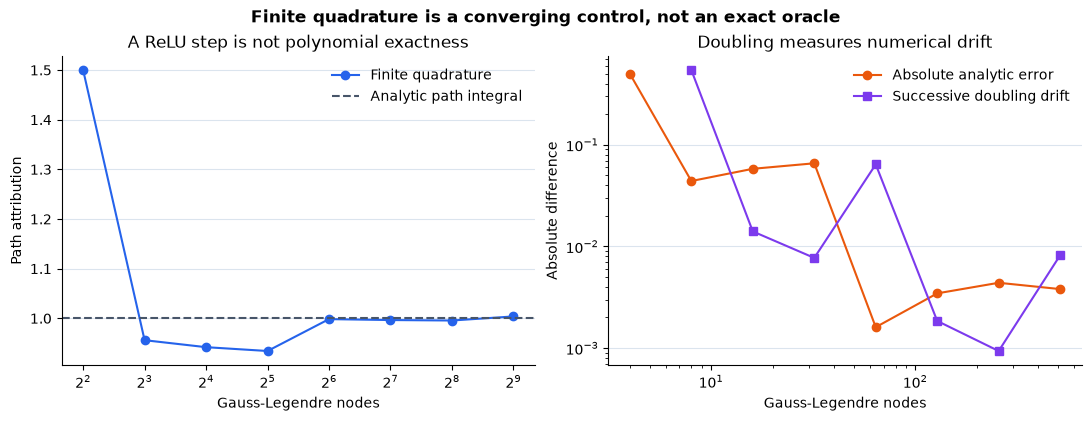

In [30]:
quadrature_check = diagnose_quadrature(
    gauss_legendre_pairs,
    input_gradients,
)
show_figure(plots.plot_quadrature_doubling(quadrature_check), "07_quadrature_doubling")


### Why averaging attributions is not using the mean baseline

For $f(z)=\operatorname{ReLU}(z)$, $x=2$, and background `(-2,1)`, the two complete path
attributions are `(2,1)`. Their average is `1.5`, and the full-background base is
`mean(0,1)=0.5`, so `0.5+1.5=2`. The mean baseline is `-0.5`, whose single path attribution is
`2`. Nonlinearity sits inside the baseline average:

$$
\mathbb E_b[\operatorname{IG}(x;b)]
\ne \operatorname{IG}(x;\mathbb E[b]).
$$


In [31]:
def diagnose_background_average(gauss_legendre_pairs_fn):
    model = _relu_model()
    query = t.tensor([[2.0]], dtype=DTYPE)
    background = t.tensor([[-2.0], [1.0]], dtype=DTYPE)
    mean_background = background.mean(dim=0, keepdim=True)
    pair_256 = gauss_legendre_pairs_fn(model, query, background, 256)[0, :, 0]
    pair_512 = gauss_legendre_pairs_fn(model, query, background, 512)[0, :, 0]
    mean_reference_512 = gauss_legendre_pairs_fn(model, query, mean_background, 512)[0, 0, 0]
    return {
        "background": background[:, 0],
        "pair_256": pair_256,
        "pair_512": pair_512,
        "pair_expected": t.tensor([2.0, 1.0], dtype=DTYPE),
        "mean_pair": pair_512.mean(),
        "mean_reference": mean_reference_512,
        "expected_mean_pair": t.tensor(1.5, dtype=DTYPE),
        "expected_mean_reference": t.tensor(2.0, dtype=DTYPE),
        "base": _prediction(model, background).mean(),
        "mean_reference_base": _prediction(model, mean_background)[0],
        "quadrature_drift": (pair_512 - pair_256).abs(),
    }


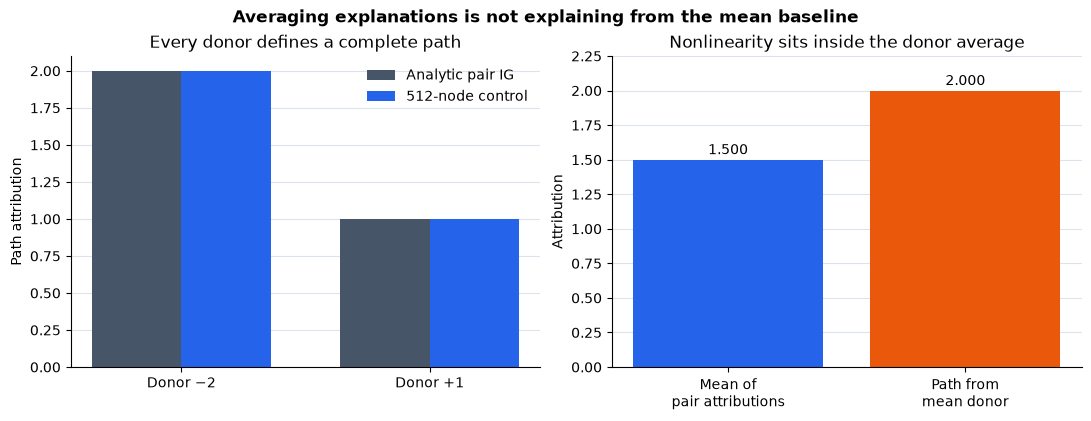

In [32]:
background_check = diagnose_background_average(gauss_legendre_pairs)
show_figure(plots.plot_background_average(background_check), "08_background_average")


## 8️⃣ Make Gaussian query noise part of the method call

Some GradientSHAP implementations perturb the query before drawing a path. With
$\epsilon\sim\mathcal N(0,\sigma^2I)$ and $\tilde x=x+\epsilon$, the retained sample is

$$
C_{ki}^{\sigma}
=(\tilde x_{ki}-b_{ki})
\partial_i f\bigl(b_k+\alpha_k(\tilde x_k-b_k)\bigr).
$$

Under the path assumptions, its population sum is

$$
\sum_i \operatorname{EG}^{\sigma}_i(x;B)
=\mathbb E_\epsilon[f(x+\epsilon)]-\mathbb E_b[f(b)],
$$

which is generally not the clean target $f(x)-\mathbb E_b[f(b)]$. Noise is therefore more than a
variance setting: it defines an average over a distribution of nearby queries.

For $f(z)=\operatorname{ReLU}(z)$, clean query $x=0$, donor $b=-1$, and
$\epsilon\sim\mathcal N(0,\sigma^2)$,

$$
\mathbb E[\operatorname{ReLU}(\epsilon)]-\operatorname{ReLU}(-1)
=\frac{\sigma}{\sqrt{2\pi}}.
$$

At $\sigma=1$, the noisy target is about `0.3989422804`, while the clean target is zero. Comparing
the noisy attribution sum with zero and calling the difference a completeness failure would be a
category error.

### Exercise 8 — `noisy_expected_gradient_samples`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 15-20 minutes on this exercise.
> ```

Accept the noise tensor explicitly rather than sampling inside the method. Use it in both the noisy
query and displacement. For an exact zero noise tensor, the result must equal the clean estimator
bitwise under the same schedule.


In [33]:
def noisy_expected_gradient_samples(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    noise: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Use x+noise in point and delta, targeting the noise-smoothed query output."""
    points, delta = interpolate_paths(x, background, indices, alpha, noise)
    gradients = input_gradients(model, points, forward_batch)
    return gradients * delta



tests.test_noisy_expected_gradient_samples(noisy_expected_gradient_samples)


All tests in test_noisy_expected_gradient_samples passed!


<details><summary>Help - reuse interpolation rather than adding noise afterward</summary>

Call `interpolate_paths(..., noise=noise)`, differentiate those points, and multiply by the returned
noisy displacements. Adding noise to a finished clean attribution or only to its gradient point does
not implement the equation above.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_noisy_expected_gradient_samples passed!
```

Zero noise matches clean samples exactly. A fixed standard-normal schedule approaches
$\sigma/\sqrt{2\pi}$ within its ordinary Monte Carlo uncertainty.

</details>

<details><summary>Interpretation</summary>

The supplied noise array makes the estimand auditable and keeps global Torch RNG state irrelevant.
A library option named `stdevs` or `local_smoothing` still needs its precise placement checked in
source: where noise enters determines the target.

</details>

<details><summary>Solution</summary>

```python
def noisy_expected_gradient_samples(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    noise: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Use x+noise in point and delta, targeting the noise-smoothed query output."""
    points, delta = interpolate_paths(x, background, indices, alpha, noise)
    gradients = input_gradients(model, points, forward_batch)
    return gradients * delta
```

</details>


In [34]:
def noise_fixture(samples=65_536):
    rng = np.random.default_rng(161512)
    return {
        "model": _relu_model(),
        "query": t.tensor([[0.0]], dtype=DTYPE),
        "background": t.tensor([[-1.0]], dtype=DTYPE),
        "indices": t.zeros((1, samples), dtype=t.int64),
        "alpha": t.tensor(rng.random((1, samples)), dtype=DTYPE),
        "standard_normal": t.tensor(rng.standard_normal((1, samples, 1)), dtype=DTYPE),
        "sigmas": t.tensor([0.0, 0.25, 0.50, 1.0], dtype=DTYPE),
    }


In [35]:
def diagnose_noise_target(
    noisy_expected_gradient_samples_fn,
    expected_gradient_samples_fn,
    summarize_expected_gradients_fn,
):
    fixture = noise_fixture()
    clean = expected_gradient_samples_fn(
        fixture["model"],
        fixture["query"],
        fixture["background"],
        fixture["indices"],
        fixture["alpha"],
    )
    estimates, standard_errors = [], []
    zero_samples = None
    for sigma in fixture["sigmas"]:
        noise = sigma * fixture["standard_normal"]
        samples = noisy_expected_gradient_samples_fn(
            fixture["model"],
            fixture["query"],
            fixture["background"],
            fixture["indices"],
            fixture["alpha"],
            noise,
        )
        mean, standard_error = summarize_expected_gradients_fn(samples, (samples.shape[1],))
        estimates.append(mean[0, 0, 0])
        standard_errors.append(standard_error[0, 0, 0])
        if float(sigma) == 0.0:
            zero_samples = samples
    estimates = t.stack(estimates)
    standard_errors = t.stack(standard_errors)
    analytic = fixture["sigmas"] / math.sqrt(2 * math.pi)
    return {
        "sigmas": fixture["sigmas"],
        "estimates": estimates,
        "standard_errors": standard_errors,
        "analytic_smoothed_target": analytic,
        "clean_target": t.zeros_like(analytic),
        "clean_residual": estimates,
        "smoothed_residual": estimates - analytic,
        "zero_noise_equal": bool(t.equal(clean, zero_samples)),
        "samples": int(fixture["alpha"].shape[1]),
    }


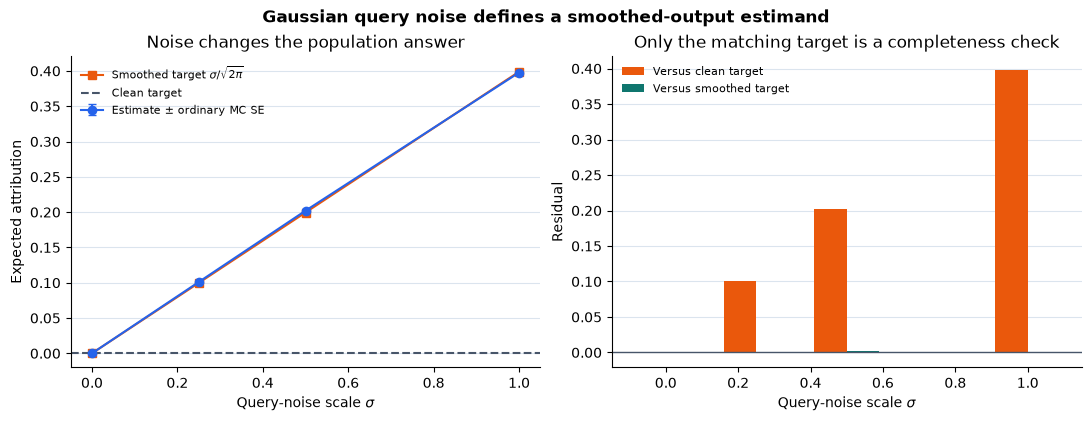

In [36]:
noise_check = diagnose_noise_target(
    noisy_expected_gradient_samples,
    expected_gradient_samples,
    summarize_expected_gradients,
)
show_figure(plots.plot_noise_target(noise_check), "09_gaussian_target_shift")


## 9️⃣ Turn a global attribution order into a coalition intervention

Expected Gradients follows continuous diagonal paths. A replacement curve instead follows a
sequence of discrete feature coalitions. Given a complete `(N,2**D)` coalition table, an order
$j_0,\ldots,j_{D-1}$ defines insertion masks

$$
0,\quad 2^{j_0},\quad 2^{j_0}+2^{j_1},\quad\ldots,\quad 2^D-1,
$$

and deletion masks in reverse from the full coalition. Looking up their raw values exposes what the
model does under donor replacement without pretending the ranking and game are the same object.

The primary audit study ranks each method once by mean absolute attribution over all 153 explanation
rows, fixes those global orders, then applies them to every audit row. The default local play may
instead order one row by `sign(f(x)-base) * phi`; that exploratory ranking cannot support a new
confirmatory audit claim.

### Exercise 9 — `ranked_coalition_curves`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 30-40 minutes on this exercise.
> ```

Return raw insertion and deletion values, their integer masks, and the feature order. Validate an
explicit order as a row-wise permutation. If `orders=None`, derive the local signed order with a
stable feature-index tie break.


In [37]:
def ranked_coalition_curves(
    values: Tensor,
    phi: Tensor,
    orders: Tensor | None = None,
) -> dict[str, Tensor]:
    """Gather raw insertion and deletion prefixes from complete coalition tables."""
    _eg_float_tensor("values", values, 2)
    _eg_float_tensor("phi", phi, 2)
    n_rows, size = values.shape
    n_features = size.bit_length() - 1
    if n_features < 1 or size != 2**n_features or phi.shape != (n_rows, n_features):
        raise ValueError("values must be (N,2**D) and phi must be (N,D), with D >= 1.")

    if orders is None:
        direction = t.where(values[:, -1] - values[:, 0] >= 0, 1.0, -1.0)[:, None]
        orders = t.argsort(direction * phi, dim=1, descending=True, stable=True)
    else:
        _eg_index_tensor("orders", orders, 2)
        if orders.shape != (n_rows, n_features):
            raise ValueError("orders must have shape (rows, features).")
        expected = t.arange(n_features, dtype=t.int64).expand(n_rows, n_features)
        if not t.equal(orders.sort(dim=1).values, expected):
            raise ValueError("Every order row must contain each feature exactly once.")
        orders = orders.clone()

    insertion_masks = t.zeros((n_rows, n_features + 1), dtype=t.int64)
    deletion_masks = t.full((n_rows, n_features + 1), size - 1, dtype=t.int64)
    for step in range(n_features):
        bit = 1 << orders[:, step]
        insertion_masks[:, step + 1] = insertion_masks[:, step] | bit
        deletion_masks[:, step + 1] = deletion_masks[:, step] ^ bit
    return {
        "orders": orders,
        "insertion_masks": insertion_masks,
        "deletion_masks": deletion_masks,
        "insertion": values.gather(1, insertion_masks),
        "deletion": values.gather(1, deletion_masks),
    }



tests.test_ranked_coalition_curves(ranked_coalition_curves)


All tests in test_ranked_coalition_curves passed!


<details><summary>Help - accumulate one feature bit per step</summary>

Initialize insertion masks to zero and deletion masks to `2**D-1`. At each step, convert the next
feature index to `1 << index`, add that bit to insertion, and remove it from deletion. Use `gather`
to read the corresponding coalition values.

</details>

<details><summary>Common bug - treating a replacement curve as an exactness score</summary>

A ranking that rises quickly can still come from an attribution vector far from exact Shapley.
Interactions can also make insertion or deletion nonmonotone. Curves measure model behavior along
one ordered computational intervention; they do not prove that the ranking is uniquely correct.

</details>

<details><summary>Expected output</summary>

```text
All tests in test_ranked_coalition_curves passed!
```

The additive fixture returns exact prefix values and a dummy-feature plateau. The random-order
control retains every declared order instead of selecting a favorable comparison.

</details>

<details><summary>Interpretation</summary>

The attribution and intervention questions are now deliberately separate. Expected Gradients may
be exact for its path expectation, exact Shapley is exact for the declared feature game, and a
replacement curve asks how one ranking traverses that game.

</details>

<details><summary>Solution</summary>

```python
def ranked_coalition_curves(
    values: Tensor,
    phi: Tensor,
    orders: Tensor | None = None,
) -> dict[str, Tensor]:
    """Gather raw insertion and deletion prefixes from complete coalition tables."""
    _eg_float_tensor("values", values, 2)
    _eg_float_tensor("phi", phi, 2)
    n_rows, size = values.shape
    n_features = size.bit_length() - 1
    if n_features < 1 or size != 2**n_features or phi.shape != (n_rows, n_features):
        raise ValueError("values must be (N,2**D) and phi must be (N,D), with D >= 1.")

    if orders is None:
        direction = t.where(values[:, -1] - values[:, 0] >= 0, 1.0, -1.0)[:, None]
        orders = t.argsort(direction * phi, dim=1, descending=True, stable=True)
    else:
        _eg_index_tensor("orders", orders, 2)
        if orders.shape != (n_rows, n_features):
            raise ValueError("orders must have shape (rows, features).")
        expected = t.arange(n_features, dtype=t.int64).expand(n_rows, n_features)
        if not t.equal(orders.sort(dim=1).values, expected):
            raise ValueError("Every order row must contain each feature exactly once.")
        orders = orders.clone()

    insertion_masks = t.zeros((n_rows, n_features + 1), dtype=t.int64)
    deletion_masks = t.full((n_rows, n_features + 1), size - 1, dtype=t.int64)
    for step in range(n_features):
        bit = 1 << orders[:, step]
        insertion_masks[:, step + 1] = insertion_masks[:, step] | bit
        deletion_masks[:, step + 1] = deletion_masks[:, step] ^ bit
    return {
        "orders": orders,
        "insertion_masks": insertion_masks,
        "deletion_masks": deletion_masks,
        "insertion": values.gather(1, insertion_masks),
        "deletion": values.gather(1, deletion_masks),
    }
```

</details>


In [38]:
def threshold_fixture():
    return {
        "model": _threshold_model(),
        "query": t.tensor([[1.0, 1.0]], dtype=DTYPE),
        "background": t.tensor([[0.0, 0.0]], dtype=DTYPE),
        "coalition_values": t.tensor([[0.0, 0.0, 0.0, 1.0]], dtype=DTYPE),
        "exact_shapley": t.tensor([[0.5, 0.5]], dtype=DTYPE),
        "analytic_path": t.tensor([[2 / 3, 1 / 3]], dtype=DTYPE),
        "necessity_drop": t.tensor([1.0, 1.0], dtype=DTYPE),
    }


In [39]:
def kink_fixture():
    first = nn.Sequential(
        _linear([[0.0, 1.0], [-1.0, 1.0]], [0.0, 0.0]),
        nn.ReLU(),
        _linear([[1.0, -1.0]], [0.0]),
    ).eval()
    mirrored = nn.Sequential(
        _linear([[1.0, 0.0], [1.0, -1.0]], [0.0, 0.0]),
        nn.ReLU(),
        _linear([[1.0, -1.0]], [0.0]),
    ).eval()
    return {
        "models": {"x1 route": first, "x0 route": mirrored},
        "query": t.tensor([[1.0, 1.0]], dtype=DTYPE),
        "background": t.tensor([[0.0, 0.0]], dtype=DTYPE),
        "binary_inputs": t.tensor(
            [[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], dtype=DTYPE
        ),
        "expected_binary": t.tensor([0.0, 0.0, 0.0, 1.0], dtype=DTYPE),
        "exact_shapley": t.tensor([[0.5, 0.5]], dtype=DTYPE),
    }


In [40]:
def replacement_fixture():
    contributions = t.tensor([3.0, -2.0, 0.0], dtype=DTYPE)
    masks = t.arange(8, dtype=t.int64)
    present = (masks[:, None].bitwise_and(1 << t.arange(3)) != 0).to(DTYPE)
    return {
        "values": (10.0 + present @ contributions).reshape(1, -1),
        "phi": contributions.reshape(1, -1),
        "all_orders": t.tensor(
            [[0, 1, 2], [0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]],
            dtype=t.int64,
        ),
    }


In [41]:
def diagnose_path_vs_coalition(gauss_legendre_pairs_fn, ranked_coalition_curves_fn):
    threshold = threshold_fixture()
    path_256 = gauss_legendre_pairs_fn(
        threshold["model"], threshold["query"], threshold["background"], 256
    ).mean(dim=1)
    path_512 = gauss_legendre_pairs_fn(
        threshold["model"], threshold["query"], threshold["background"], 512
    ).mean(dim=1)
    threshold_orders = t.tensor([[0, 1], [1, 0]], dtype=t.int64)
    threshold_curves = [
        ranked_coalition_curves_fn(
            threshold["coalition_values"], path_512, order.reshape(1, -1)
        )
        for order in threshold_orders
    ]

    kink = kink_fixture()
    kink_phi, kink_outputs = {}, {}
    for name, model in kink["models"].items():
        kink_phi[name] = gauss_legendre_pairs_fn(
            model, kink["query"], kink["background"], 32
        ).mean(dim=1)
        kink_outputs[name] = _prediction(model, kink["binary_inputs"])

    replacement = replacement_fixture()
    local_curve = ranked_coalition_curves_fn(replacement["values"], replacement["phi"])
    random_curves = [
        ranked_coalition_curves_fn(
            replacement["values"], replacement["phi"], order.reshape(1, -1)
        )
        for order in replacement["all_orders"]
    ]
    return {
        "threshold": {
            "path_256": path_256,
            "path_512": path_512,
            "quadrature_drift": (path_512 - path_256).abs(),
            "analytic_path": threshold["analytic_path"],
            "exact_shapley": threshold["exact_shapley"],
            "necessity_drop": threshold["necessity_drop"],
            "orders": threshold_orders,
            "curves": threshold_curves,
        },
        "kink": {
            "binary_inputs": kink["binary_inputs"],
            "expected_binary": kink["expected_binary"],
            "outputs": kink_outputs,
            "path_phi": kink_phi,
            "exact_shapley": kink["exact_shapley"],
        },
        "replacement": {
            "values": replacement["values"],
            "phi": replacement["phi"],
            "local_curve": local_curve,
            "random_curves": random_curves,
        },
    }


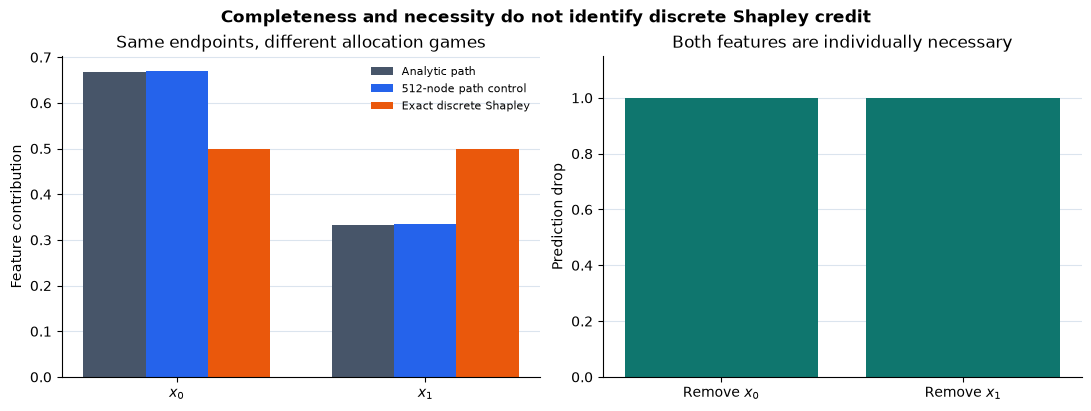

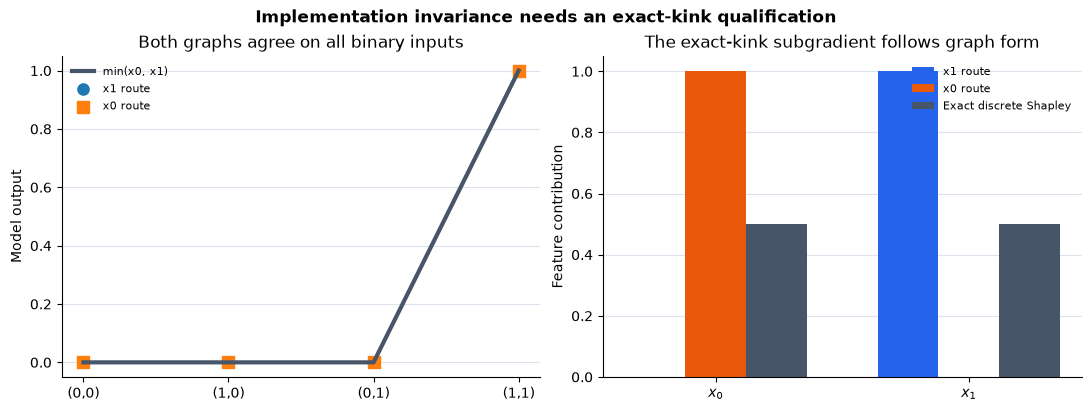

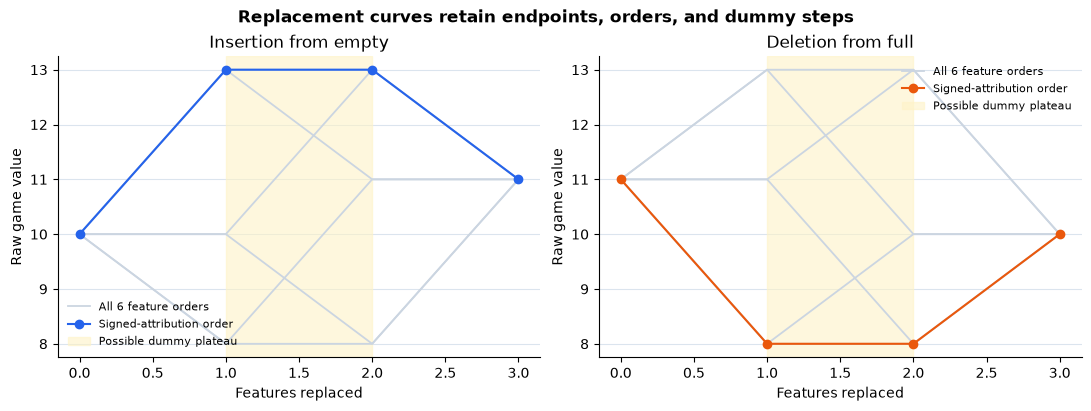

In [42]:
game_check = diagnose_path_vs_coalition(
    gauss_legendre_pairs,
    ranked_coalition_curves,
)
show_figure(
    plots.plot_path_vs_coalition(game_check),
    "10_path_vs_coalition",
)
show_figure(
    plots.plot_kink_representation(game_check),
    "11_kink_representation",
)
show_figure(
    plots.plot_replacement_fixture(game_check),
    "12_replacement_fixture",
)


### The threshold control: complete paths are not discrete Shapley

For

$$
f(x_0,x_1)=\operatorname{ReLU}(2x_0+x_1-2),\qquad x=(1,1),\quad b=(0,0),
$$

the diagonal path becomes active after $\alpha=2/3$. Its Expected Gradients allocation is
`(2/3,1/3)`. The four donor-replacement coalition values are `(0,0,0,1)`, whose exact Shapley
allocation is `(1/2,1/2)`. Both sum to one, and replacing either feature alone drops the output from
one to zero. Completeness and single-feature causal necessity do not force equal credit across these
two games.

### The exact-kink qualification

On nonnegative inputs,

$$
\min(x_0,x_1)=x_1-\operatorname{ReLU}(x_1-x_0)
=x_0-\operatorname{ReLU}(x_0-x_1).
$$

Along the path from `(0,0)` to `(1,1)`, both ReLU arguments stay exactly at the nondifferentiable
kink. PyTorch's zero derivative assigns `(0,1)` to the first graph and `(1,0)` to the mirrored
graph, while the discrete game gives `(1/2,1/2)`. This does not refute almost-everywhere
implementation invariance away from kinks. It exposes that an exact nondifferentiable path needs a
subgradient convention, and equivalent graphs can encode different conventions there. All four
binary inputs agree in output, and each feature is necessary at `(1,1)`.


In [43]:
methods = SimpleNamespace(
    sample_path_schedule=sample_path_schedule,
    interpolate_paths=interpolate_paths,
    input_gradients=input_gradients,
    expected_gradient_samples=expected_gradient_samples,
    summarize_expected_gradients=summarize_expected_gradients,
    expected_gradients=expected_gradients,
    gauss_legendre_pairs=gauss_legendre_pairs,
    noisy_expected_gradient_samples=noisy_expected_gradient_samples,
    ranked_coalition_curves=ranked_coalition_curves,
)


### Try It Yourself 1 — move a path through the gate

Edit the query, donor, weights, bias, alpha schedule, and sample count. Recompute the path-gradient
samples, quadrature control, exact four-coalition Shapley, and both single-feature replacements.
Avoid placing a hand-derived test alpha exactly on the ReLU kink.


In [44]:
def threshold_play(
    methods,
    weights: Sequence[float] = (2.0, 1.0),
    bias: float = -2.0,
    query: Sequence[float] = (1.0, 1.0),
    reference: Sequence[float] = (0.0, 0.0),
    samples: int = 512,
    seed: int = 161510,
):
    schedule_fn = _method(methods, "sample_path_schedule")
    sample_fn = _method(methods, "expected_gradient_samples")
    summarize_fn = _method(methods, "summarize_expected_gradients")
    quadrature_fn = _method(methods, "gauss_legendre_pairs")
    curves_fn = _method(methods, "ranked_coalition_curves")
    model = _threshold_model(weights, bias)
    query_tensor = t.as_tensor(query, dtype=DTYPE).reshape(1, -1)
    reference_tensor = t.as_tensor(reference, dtype=DTYPE).reshape(1, -1)
    if query_tensor.shape != reference_tensor.shape:
        raise ValueError("query and reference must have the same feature count.")
    if query_tensor.shape[1] != len(weights):
        raise ValueError("weights must contain one value per query feature.")
    indices, alpha = schedule_fn(t.tensor([0], dtype=t.int64), 1, samples, seed)
    draws = sample_fn(model, query_tensor, reference_tensor, indices, alpha)
    mean, standard_error = summarize_fn(draws, (samples,))
    quadrature = quadrature_fn(model, query_tensor, reference_tensor, 512).mean(dim=1)

    feature_count = query_tensor.shape[1]
    if feature_count != 2:
        raise ValueError("The editable teaching play currently requires exactly two features.")
    masks = t.arange(4, dtype=t.int64)
    present = masks[:, None].bitwise_and(1 << t.arange(2)) != 0
    hybrids = t.where(present, query_tensor, reference_tensor)
    values = _prediction(model, hybrids).reshape(1, -1)
    exact = _two_feature_shapley(values).reshape(1, -1)
    curves = {
        "expected_gradients": curves_fn(values, mean[0]),
        "exact_shapley": curves_fn(values, exact),
    }
    return {
        "weights": t.as_tensor(weights, dtype=DTYPE),
        "bias": float(bias),
        "query": query_tensor,
        "reference": reference_tensor,
        "alpha": alpha,
        "draws": draws,
        "mean": mean[0],
        "standard_error": standard_error[0],
        "quadrature": quadrature,
        "coalition_values": values,
        "exact_shapley": exact,
        "prediction": _prediction(model, query_tensor)[0],
        "base": _prediction(model, reference_tensor)[0],
        "curves": curves,
        "samples": samples,
        "seed": seed,
    }

def run_diagnostics(methods=None):
    schedule = diagnose_schedule(_method(methods, "sample_path_schedule"))
    interpolation = diagnose_interpolation(_method(methods, "interpolate_paths"))
    gradients = diagnose_gradients(_method(methods, "input_gradients"))
    samples = diagnose_expected_gradient_samples(
        _method(methods, "expected_gradient_samples"),
        _method(methods, "sample_path_schedule"),
    )
    convergence = diagnose_convergence(
        _method(methods, "sample_path_schedule"),
        _method(methods, "expected_gradient_samples"),
        _method(methods, "summarize_expected_gradients"),
    )
    estimator = diagnose_expected_gradients(
        _method(methods, "expected_gradients"),
        _method(methods, "sample_path_schedule"),
    )
    quadrature = diagnose_quadrature(
        _method(methods, "gauss_legendre_pairs"),
        _method(methods, "input_gradients"),
    )
    background = diagnose_background_average(_method(methods, "gauss_legendre_pairs"))
    noise = diagnose_noise_target(
        _method(methods, "noisy_expected_gradient_samples"),
        _method(methods, "expected_gradient_samples"),
        _method(methods, "summarize_expected_gradients"),
    )
    game = diagnose_path_vs_coalition(
        _method(methods, "gauss_legendre_pairs"),
        _method(methods, "ranked_coalition_curves"),
    )
    namespace = methods
    if namespace is None:
        from . import gradientshap_methods

        namespace = gradientshap_methods
    play = threshold_play(namespace)
    return {
        "schedule": schedule,
        "interpolation": interpolation,
        "gradients": gradients,
        "samples": samples,
        "convergence": convergence,
        "estimator": estimator,
        "quadrature": quadrature,
        "background": background,
        "noise": noise,
        "game": game,
        "threshold_play": play,
    }


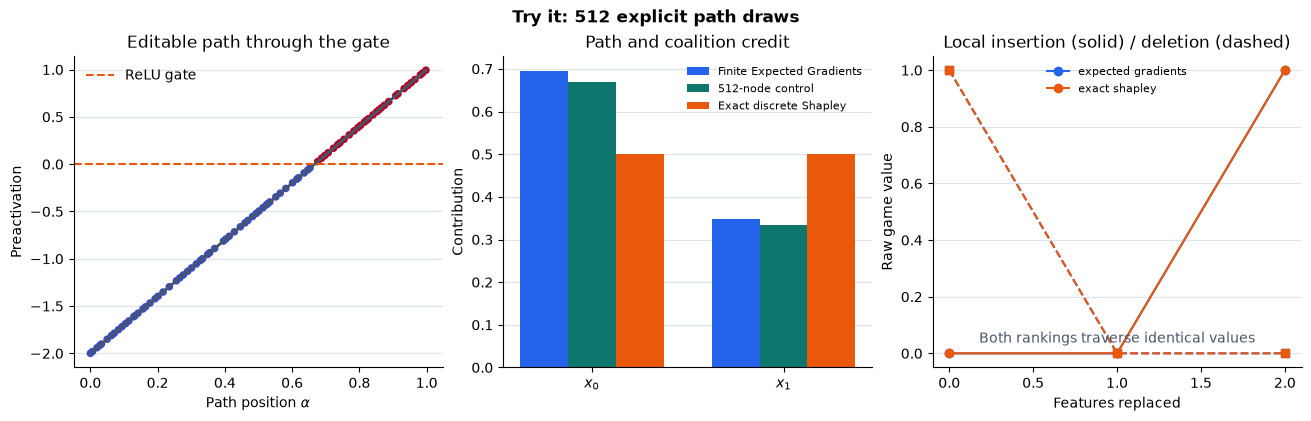

In [45]:
tiny_play = threshold_play(
    methods,
    weights=(2.0, 1.0),
    bias=-2.0,
    query=(1.0, 1.0),
    reference=(0.0, 0.0),
    samples=512,
    seed=161510,
)
show_figure(plots.plot_threshold_play(tiny_play), "13_threshold_play")


<details><summary>Ideas to try</summary>

- Make both weights equal and check which symmetries the query and reference must also satisfy.
- Move the bias until a finite schedule has only active or only inactive draws.
- Double the sample count while preserving the old prefix; compare the actual error with the SE.
- Put the path exactly on a kink, then perturb one coordinate by `1e-8` and inspect the derivative
  convention.

</details>


## The frozen-design real study

> **Execution boundary.** The independently reviewed zero-run freeze binds `protocol.md`, the
> manifest, and the data implementation before fitting. The cells below reproduce all 21 section
> 16.14 state hashes, persist the fitted and prepared study before the literal audit load, and then
> evaluate every held-out recipe. This ordering keeps explanation-side choices separate from the
> audit evidence.

The intended study holds the predictors and data fixed so the attribution method is the variable:

- the same 1,030 UCI Concrete rows and recipe-disjoint 758/153/119 split as section 16.14;
- the same three clean and three shuffled-target `8 -> 32 -> 32 -> 1` ReLU functions plus ridge;
- raw feature inputs, raw MPa outputs, and state-hash parity with the section 16.14 predictors;
- all seven models and all 272 held-out rows, with no selected-error subset;
- the same primary 64 intact donors, nested sizes 16 and 128, and two independent 64-row designs;
- nested Monte Carlo budgets `(8,32,128,512,2048)` on one literal row-stable schedule;
- 256- and 512-node all-background quadrature retained separately;
- exact 256-coalition Shapley, DeepSHAP, and endpoint gradient-times-delta as distinct comparisons;
- Gaussian scales `(0,0.02,0.10)` in train-standardized input units, mapped back to raw units;
- global feature orders learned from 153 explanation rows before audit values are loaded;
- 100 fixed random feature orders for the 119-row audit replacement experiment.

The reused predictors isolate method behavior but do not constitute an independent model or dataset
replication. The frozen protocol refits them from source, verifies all 21 initial, standardized, and
raw-folded state hashes against section 16.14, and stops before attribution if any identity differs.


The visible study source will be split into short cells for state reconstruction, schedule creation,
path evaluation, quadrature, exact-game comparisons, background/noise evaluation, and replacement
curves. Mechanical schema validation may be imported; the scientific call flow and every meaningful
transformation must remain visible.


In [46]:
from part14_deepshap import deepshap_methods as deep_methods
from part15_gradientshap.gradientshap_study import (
    _batched_prediction,
    _checked_curves,
    _clone_state,
    _combine_baselines,
    _combine_mc,
    _combine_primary,
    _combine_quadrature,
    _fixed_random_orders,
    _float_tensor,
    _folding_error,
    _identity_hash,
    _ids_tensor,
    _normalization_tensors,
    _output_tensor,
    _require_disjoint_ids,
    _require_namespace,
    _rows,
    _seed_words,
    _state_shapes,
    _validate_evaluation_inputs,
    _validate_fitted,
)


In [47]:
FEATURES = 8

HIDDEN = 32

TRAINING_STEPS = 800

LEARNING_RATE = 0.003

WEIGHT_DECAY = 0.0001

RIDGE_PENALTY = 0.01

MODEL_KEYS = (
    "clean_0",
    "clean_1",
    "clean_2",
    "shuffled_0",
    "shuffled_1",
    "shuffled_2",
    "ridge",
)

MODEL_SEEDS = (161410, 161411, 161412)

SHUFFLE_SEEDS = (161420, 161421, 161422)

BACKGROUND_SPECS = {
    "primary64": (161460, 64),
    "nested16": (161460, 16),
    "nested128": (161460, 128),
    "independent64_a": (161461, 64),
    "independent64_b": (161462, 64),
}

BUDGETS = (8, 32, 128, 512, 2048)

QUADRATURE_NODES = (256, 512)

NOISE_SIGMAS = (0.0, 0.02, 0.10)

PRIMARY_SCHEDULE_SEED = 161510

REPLICATE_SCHEDULE_SEED = 161511

NOISE_SCHEDULE_SEED = 161512

REFERENCE_SEEDS = {"shap": 161513, "captum_numpy": 161514, "captum_torch": 161515}

RANDOM_ORDER_SEED = 161480

REPLICATES = 64

REPLICATE_MODELS = ("clean_0", "shuffled_0", "ridge")

PATH_DISTANCE_SAMPLES = 128

COALITION_DISTANCE_DONORS = 8

FORWARD_BATCH = 32_768

DISTANCE_BATCH = 1_024


In [48]:
FEATURE_NAMES = (
    "Cement",
    "Slag",
    "Fly ash",
    "Water",
    "Superplasticizer",
    "Coarse aggregate",
    "Fine aggregate",
    "Age",
)

MODEL_LABELS = {
    **{f"clean_{i}": f"clean MLP seed {seed}" for i, seed in enumerate(MODEL_SEEDS)},
    **{
        f"shuffled_{i}": f"shuffled MLP seed {seed}"
        for i, seed in enumerate(MODEL_SEEDS)
    },
    "ridge": "ridge control",
}

UNITS = {
    "input": "source feature units",
    "target": "MPa",
    "prediction": "MPa",
    "base": "MPa",
    "attribution": "MPa",
    "game": "MPa",
    "squared_error": "MPa squared",
    "distance": "train-standardized Euclidean distance",
}

METHOD_NAMES = (
    "sample_path_schedule",
    "interpolate_paths",
    "input_gradients",
    "expected_gradient_samples",
    "summarize_expected_gradients",
    "expected_gradients",
    "gauss_legendre_pairs",
    "noisy_expected_gradient_samples",
    "ranked_coalition_curves",
)

DEEP_METHOD_NAMES = (
    "rescale_multipliers",
    "background_deepshap",
    "coalition_masks",
    "coalition_values",
    "exact_shapley",
    "gradient_delta",
)


The data loader supplies raw rows and identities. The next function reconstructs a supported raw
`nn.Sequential` from a retained state dictionary; normalization is folded into the model weights,
so every later attribution stays in raw feature and raw MPa units.


In [49]:
def _model_from_state(record: Mapping[str, Any]) -> t.nn.Sequential:
    """Rebuild one supported raw-input/raw-MPa model from its retained state."""
    if not isinstance(record, Mapping) or not {"kind", "state"} <= set(record):
        raise TypeError("A fitted model record must contain kind and state.")
    kind = str(record["kind"])
    state = _clone_state(record["state"])
    shapes = _state_shapes(kind)
    if set(state) != set(shapes):
        raise ValueError(f"{kind} state has unexpected parameter names.")
    if any(tuple(state[name].shape) != shape for name, shape in shapes.items()):
        raise ValueError(f"{kind} state has an unexpected parameter shape.")
    if kind == "mlp":
        model = t.nn.Sequential(
            t.nn.Linear(FEATURES, HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(HIDDEN, HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(HIDDEN, 1, dtype=t.float64),
        )
    else:
        model = t.nn.Sequential(t.nn.Linear(FEATURES, 1, dtype=t.float64))
    model.load_state_dict(state, strict=True)
    model.eval()
    return model


### Refit the seven known predictors

Compute normalization only from the 758 training rows. The six neural controls use the exact fixed
seeds and 800 full-batch updates; three receive clean targets and three receive fixed shuffled
targets. Folding is explicit so the standardized and raw-unit functions can be compared before any
attribution is calculated.


In [50]:
def _training_normalization(train: Mapping[str, Any]) -> dict[str, t.Tensor]:
    """Compute the four train-only population moments used by every fit."""
    x_raw, y_raw, _ = _rows(train, "train")
    normalization = {
        "x_mean": x_raw.mean(0),
        "x_std": x_raw.std(0, correction=0),
        "y_mean": y_raw.mean(),
        "y_std": y_raw.std(correction=0),
    }
    _normalization_tensors(normalization)
    return normalization


In [51]:
def _train_mlp(
    model: t.nn.Sequential,
    x_standardized: t.Tensor,
    target_standardized: t.Tensor,
) -> tuple[dict[str, t.Tensor], t.Tensor]:
    """Run exactly 800 full-batch float64 Adam updates and retain every loss."""
    optimizer = t.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    losses: list[t.Tensor] = []
    model.train()
    with t.enable_grad():
        for _ in range(TRAINING_STEPS):
            optimizer.zero_grad()
            loss = (model(x_standardized).squeeze(-1) - target_standardized).square().mean()
            loss.backward()
            optimizer.step()
            losses.append(loss.detach().clone())
    return _clone_state(model.state_dict()), t.stack(losses)

def _fold_mlp_state(
    state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold train normalization into the first and last MLP affine layers."""
    folded = _clone_state(state)
    if set(folded) != set(_state_shapes("mlp")):
        raise ValueError("Cannot fold an unexpected MLP state.")
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    first_weight = folded["0.weight"].clone()
    folded["0.weight"] = first_weight / x_std[None, :]
    folded["0.bias"] = folded["0.bias"] - first_weight @ (x_mean / x_std)
    folded["4.weight"] = y_std * folded["4.weight"]
    folded["4.bias"] = y_std * folded["4.bias"] + y_mean
    return folded

def _fold_ridge_state(
    state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold standardized ridge coefficients into raw feature and MPa units."""
    folded = _clone_state(state)
    if set(folded) != set(_state_shapes("ridge")):
        raise ValueError("Cannot fold an unexpected ridge state.")
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    weight = folded["0.weight"].clone()
    folded["0.weight"] = y_std * weight / x_std[None, :]
    folded["0.bias"] = y_std * (
        folded["0.bias"] - (weight * (x_mean / x_std)[None, :]).sum(1)
    ) + y_mean
    return folded


The MLP fit retains its initial state, standardized state, folded raw state, target permutation,
loss trace, and training predictions. Ridge is fitted once by the declared normal-equation solve and
provides the affine path-versus-coalition agreement control.


In [52]:
def fit_one_mlp_control(
    train: Mapping[str, Any],
    normalization: Mapping[str, Any],
    seed: int,
    shuffle_seed: int | None,
) -> dict[str, Any]:
    """Fit and fully retain one clean or shuffled 8-32-32-1 control."""
    if seed not in MODEL_SEEDS:
        raise ValueError("seed must be one of the three frozen model seeds.")
    if shuffle_seed is not None and shuffle_seed not in SHUFFLE_SEEDS:
        raise ValueError("shuffle_seed must be a frozen paired shuffle seed or None.")
    x_raw, y_raw, _ = _rows(train, "train")
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    x = (x_raw - x_mean) / x_std
    y = (y_raw - y_mean) / y_std
    t.manual_seed(seed)
    model = t.nn.Sequential(
        t.nn.Linear(FEATURES, HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(HIDDEN, HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(HIDDEN, 1, dtype=t.float64),
    )
    initial_state = _clone_state(model.state_dict())
    permutation = t.arange(len(y), dtype=t.int64)
    if shuffle_seed is not None:
        permutation = t.from_numpy(np.random.default_rng(shuffle_seed).permutation(len(y)))
    standardized_state, loss_trace = _train_mlp(model, x, y[permutation])
    raw_state = _fold_mlp_state(standardized_state, normalization)
    prediction, folding_error = _folding_error(
        "mlp", standardized_state, raw_state, normalization, x_raw
    )
    if folding_error > 1e-10:
        raise AssertionError("Raw-unit MLP folding changed its training predictions.")
    return {
        "kind": "mlp",
        "control": "clean" if shuffle_seed is None else "shuffled",
        "seed": seed,
        "initial_state": initial_state,
        "standardized_state": standardized_state,
        "state": raw_state,
        "loss_trace": loss_trace,
        "target_permutation": permutation,
        "training_targets_raw": y_raw[permutation].clone(),
        "training_prediction": prediction,
        "folding_max_abs_error": folding_error,
        "parameters": {
            "architecture": [FEATURES, HIDDEN, HIDDEN, 1],
            "steps": TRAINING_STEPS,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "optimizer": "Adam",
            "risk": "mean_squared_error",
            "batch": "full_training_split",
            "shuffle_seed": shuffle_seed,
            "dtype": "float64",
            "parameter_count": sum(value.numel() for value in raw_state.values()),
        },
    }


In [53]:
def fit_ridge_control(
    train: Mapping[str, Any], normalization: Mapping[str, Any]
) -> dict[str, Any]:
    """Solve the fixed penalty-0.01 standardized ridge normal equations once."""
    x_raw, y_raw, _ = _rows(train, "train")
    x_mean, x_std, y_mean, y_std = _normalization_tensors(normalization)
    x = (x_raw - x_mean) / x_std
    y = (y_raw - y_mean) / y_std
    design = t.cat([x, t.ones((len(x), 1), dtype=t.float64)], dim=1)
    penalty = t.eye(FEATURES + 1, dtype=t.float64) * RIDGE_PENALTY
    penalty[-1, -1] = 0.0
    coefficient = t.linalg.solve(
        design.T @ design / len(x) + penalty,
        design.T @ y / len(x),
    )
    standardized_state = {
        "0.weight": coefficient[:FEATURES][None, :].clone(),
        "0.bias": coefficient[FEATURES:].clone(),
    }
    raw_state = _fold_ridge_state(standardized_state, normalization)
    prediction, folding_error = _folding_error(
        "ridge", standardized_state, raw_state, normalization, x_raw
    )
    if folding_error > 1e-10:
        raise AssertionError("Raw-unit ridge folding changed its training predictions.")
    standard_model = _model_from_state({"kind": "ridge", "state": standardized_state})
    with t.no_grad():
        ridge_loss = (standard_model(x).squeeze(-1) - y).square().mean()
    return {
        "kind": "ridge",
        "control": "ridge",
        "seed": 0,
        "initial_state": {},
        "standardized_state": standardized_state,
        "state": raw_state,
        "loss_trace": ridge_loss[None].clone(),
        "target_permutation": t.arange(len(y), dtype=t.int64),
        "training_targets_raw": y_raw.clone(),
        "training_prediction": prediction,
        "folding_max_abs_error": folding_error,
        "parameters": {
            "penalty": RIDGE_PENALTY,
            "penalize_intercept": False,
            "risk": "mean_squared_error",
            "dtype": "float64",
            "parameter_count": FEATURES + 1,
        },
    }


In [54]:
def fit_models(train: Mapping[str, Any]) -> dict[str, Any]:
    """Refit all seven known predictors from the pinned training rows."""
    x_raw, y_raw, train_ids = _rows(train, "train")
    t.set_num_threads(4)
    t.use_deterministic_algorithms(True)
    normalization = _training_normalization(train)
    models: dict[str, Any] = {}
    for index, seed in enumerate(MODEL_SEEDS):
        models[f"clean_{index}"] = fit_one_mlp_control(
            train, normalization, seed, None
        )
    for index, seed in enumerate(MODEL_SEEDS):
        models[f"shuffled_{index}"] = fit_one_mlp_control(
            train, normalization, seed, SHUFFLE_SEEDS[index]
        )
    models["ridge"] = fit_ridge_control(train, normalization)
    for record in models.values():
        record["state_hashes"] = {
            "initial_state": tensor_mapping_sha256(record["initial_state"]),
            "standardized_state": tensor_mapping_sha256(record["standardized_state"]),
            "raw_folded_state": tensor_mapping_sha256(record["state"]),
        }
    return {
        "models": models,
        "normalization": normalization,
        "train_ids": train_ids,
        "train_x_raw": x_raw,
        "train_y_raw": y_raw,
        "units": dict(UNITS),
        "feature_names": FEATURE_NAMES,
        "model_labels": dict(MODEL_LABELS),
        "phase": "fitted_before_attribution",
    }


### Stop unless all 21 model states match section 16.14

The comparison is useful only if GradientSHAP and DeepSHAP explain identical fitted functions. The
hard gate below checks the initial, standardized, and raw-folded state of each of the seven models,
plus training identities, normalization, targets, permutations, loss traces, and predictions. A
mismatch raises before `prepare_study` can draw a path schedule.


In [55]:
def verify_16_14_reproduction(
    fitted: Mapping[str, Any], manifest: Mapping[str, Any]
) -> dict[str, Any]:
    """Hard-fail unless all 21 states and every deterministic fit identity agree."""
    _validate_fitted(fitted)
    evidence = manifest.get("known_16_14_evidence", {})
    expected_hashes = evidence.get("model_state_hashes", {})
    if tuple(expected_hashes) != MODEL_KEYS:
        raise ValueError("Manifest must contain all seven known 16.14 state records.")
    observed: dict[str, dict[str, str]] = {}
    mismatches: list[str] = []
    state_fields = {
        "initial_state": "initial_state",
        "standardized_state": "standardized_state",
        "raw_folded_state": "state",
    }
    for key in MODEL_KEYS:
        record = fitted["models"][key]
        observed[key] = {
            label: tensor_mapping_sha256(record[field])
            for label, field in state_fields.items()
        }
        for label in state_fields:
            if observed[key][label] != expected_hashes[key][label]:
                mismatches.append(f"{key}.{label}")
        if record.get("state_hashes") != observed[key]:
            mismatches.append(f"{key}.retained_state_hashes")

    expected_train_ids = t.as_tensor(manifest.get("splits", {}).get("train"), dtype=t.int64)
    train_ids_match = t.equal(fitted["train_ids"], expected_train_ids)
    if not train_ids_match:
        mismatches.append("train_ids")
    normalization = _training_normalization(
        {
            "x": fitted["train_x_raw"],
            "y": fitted["train_y_raw"],
            "ids": fitted["train_ids"],
        }
    )
    if any(
        not t.equal(normalization[name], fitted["normalization"][name])
        for name in normalization
    ):
        mismatches.append("normalization")

    recipe = manifest.get("model_recipe", {})
    training_recipe_match = (
        recipe.get("model_keys") == list(MODEL_KEYS)
        and recipe.get("model_seeds") == list(MODEL_SEEDS)
        and recipe.get("shuffle_seeds") == list(SHUFFLE_SEEDS)
        and recipe.get("training_steps") == TRAINING_STEPS
        and recipe.get("learning_rate") == LEARNING_RATE
        and recipe.get("weight_decay") == WEIGHT_DECAY
        and recipe.get("ridge_penalty") == RIDGE_PENALTY
    )
    for index, key in enumerate(MODEL_KEYS):
        record = fitted["models"][key]
        expected_permutation = t.arange(len(fitted["train_ids"]), dtype=t.int64)
        if key.startswith("shuffled_"):
            expected_permutation = t.from_numpy(
                np.random.default_rng(SHUFFLE_SEEDS[index - 3]).permutation(
                    len(fitted["train_ids"])
                )
            )
        if not t.equal(record.get("target_permutation"), expected_permutation):
            mismatches.append(f"{key}.target_permutation")
        expected_targets = fitted["train_y_raw"][expected_permutation]
        if not t.equal(record.get("training_targets_raw"), expected_targets):
            mismatches.append(f"{key}.training_targets_raw")
        expected_steps = 1 if key == "ridge" else TRAINING_STEPS
        trace = record.get("loss_trace")
        if not isinstance(trace, t.Tensor) or trace.shape != (expected_steps,):
            mismatches.append(f"{key}.loss_trace")
        with t.no_grad():
            prediction = _model_from_state(record)(fitted["train_x_raw"]).squeeze(-1)
        if not t.equal(record.get("training_prediction"), prediction):
            mismatches.append(f"{key}.training_prediction")
        if float(record.get("folding_max_abs_error", float("inf"))) > 1e-10:
            mismatches.append(f"{key}.folding_max_abs_error")
    if not training_recipe_match:
        mismatches.append("training_recipe")
    if mismatches:
        raise AssertionError(
            "16.14 reproduction mismatch before attribution: " + ", ".join(mismatches)
        )
    return {
        "status": "PASS",
        "known_section": "16.14",
        "fitted_artifact_sha256": evidence.get("fitted_artifact_sha256"),
        "model_state_hashes": observed,
        "expected_model_state_hashes": expected_hashes,
        "mismatches": (),
        "train_ids_match": train_ids_match,
        "training_recipe_match": training_recipe_match,
    }


### Fix backgrounds and one shared path schedule

All five backgrounds are selected by the frozen source-ID hash rule. Every model receives the same
K=2048 donor and alpha table for each source row, and every smaller budget is a literal prefix.


In [56]:
def _background_indices(
    train_ids: Any, manifest: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Recreate all five background index arrays and verify every donor identity."""
    ids = _ids_tensor(train_ids, len(train_ids), "train_ids")
    declared = manifest.get("backgrounds", {})
    if tuple(declared) != tuple(BACKGROUND_SPECS):
        raise ValueError("Manifest background names or order changed.")
    result: dict[str, t.Tensor] = {}
    for name, (seed, size) in BACKGROUND_SPECS.items():
        order = t.from_numpy(background_order(ids.numpy(), seed))
        indices = order[:size].clone()
        item = declared[name]
        if item.get("seed") != seed or item.get("rows") != size:
            raise ValueError(f"{name} changed its seed or donor count.")
        expected_indices = t.as_tensor(item.get("train_indices"), dtype=t.int64)
        expected_ids = t.as_tensor(item.get("source_ids"), dtype=t.int64)
        if not t.equal(indices, expected_indices) or not t.equal(ids[indices], expected_ids):
            raise ValueError(f"{name} donor indices or source identities changed.")
        result[name] = indices
    return result

def _primary_schedule(
    rows: Mapping[str, Any], background_rows: int, methods: Any
) -> dict[str, t.Tensor]:
    """Create the one shared K=2048 primary schedule for a named row block."""
    _require_namespace(methods, METHOD_NAMES, "Student methods")
    _, _, source_ids = _rows(rows, "rows")
    indices, alpha = methods.sample_path_schedule(
        source_ids, background_rows, max(BUDGETS), PRIMARY_SCHEDULE_SEED
    )
    return {"source_ids": source_ids, "baseline_index": indices, "alpha": alpha}


### Retain the estimator and its numerical control

`_monte_carlo_block` keeps every contribution draw before calculating nested means, ordinary SE,
and finite completeness residuals. `_quadrature_block` separately keeps every donor-wise 256- and
512-node path integral and their drift; 512 nodes remain a numerical control rather than truth.


In [57]:
def _monte_carlo_block(
    model: t.nn.Module,
    rows: Mapping[str, Any],
    background: t.Tensor,
    schedule: Mapping[str, t.Tensor],
    methods: Any,
) -> dict[str, Any]:
    """Retain all per-draw contributions and every declared nested prefix."""
    x, _, source_ids = _rows(rows, "rows")
    if not t.equal(source_ids, schedule["source_ids"]):
        raise ValueError("Schedule source identities do not match the explained rows.")
    samples = methods.expected_gradient_samples(
        model, x, background, schedule["baseline_index"], schedule["alpha"], FORWARD_BATCH
    )
    samples = _output_tensor(samples, (len(x), max(BUDGETS), FEATURES), "samples")
    phi_prefix, se_prefix = methods.summarize_expected_gradients(samples, BUDGETS)
    phi_prefix = _output_tensor(phi_prefix, (len(BUDGETS), len(x), FEATURES), "phi_prefix")
    se_prefix = _output_tensor(se_prefix, (len(BUDGETS), len(x), FEATURES), "se_prefix")
    with t.no_grad():
        base = model(background).squeeze(-1).mean()
        prediction = model(x).squeeze(-1)
    residual = phi_prefix.sum(-1) - (prediction[None, :] - base)
    return {
        "source_ids": source_ids,
        "baseline_index": schedule["baseline_index"],
        "alpha": schedule["alpha"],
        "samples": samples,
        "budgets": t.tensor(BUDGETS, dtype=t.int64),
        "phi_prefix": phi_prefix,
        "se_prefix": se_prefix,
        "base_full": base.detach(),
        "prediction": prediction.detach(),
        "completeness_residual_prefix": residual.detach(),
    }


In [58]:
def _quadrature_block(
    model: t.nn.Module,
    rows: Mapping[str, Any],
    background: t.Tensor,
    methods: Any,
) -> dict[str, t.Tensor]:
    """Retain donor-wise Q=256/Q=512 numerical path controls and drift."""
    x, _, _ = _rows(rows, "rows")
    low, high = QUADRATURE_NODES
    pair_low = methods.gauss_legendre_pairs(
        model, x, background, low, row_batch=4, forward_batch=FORWARD_BATCH
    )
    pair_high = methods.gauss_legendre_pairs(
        model, x, background, high, row_batch=4, forward_batch=FORWARD_BATCH
    )
    shape = (len(x), len(background), FEATURES)
    pair_low = _output_tensor(pair_low, shape, f"pair_{low}")
    pair_high = _output_tensor(pair_high, shape, f"pair_{high}")
    mean_low, mean_high = pair_low.mean(1), pair_high.mean(1)
    return {
        f"pair_{low}": pair_low,
        f"pair_{high}": pair_high,
        f"mean_{low}": mean_low,
        f"mean_{high}": mean_high,
        "drift": mean_high - mean_low,
    }


### Compare the continuous path with a discrete replacement game

For eight features we can retain all 256 coalitions and every query/coalition/donor prediction.
The same raw model and donor rows then produce exact feature Shapley, DeepSHAP, and endpoint
gradient-times-delta controls. Their differences are measured outcomes, never a parity gate.


In [59]:
def _coalition_hybrid_predictions(
    model: t.nn.Module,
    x: t.Tensor,
    background: t.Tensor,
    masks: t.Tensor,
    *,
    row_batch: int = 4,
    forward_batch: int = FORWARD_BATCH,
) -> t.Tensor:
    """Retain every query/coalition/donor prediction in bounded forward batches."""
    result = t.empty((len(x), len(masks), len(background)), dtype=t.float64)
    with t.no_grad():
        for start in range(0, len(x), row_batch):
            query = x[start : start + row_batch]
            hybrids = t.where(
                masks[None, :, None, :],
                query[:, None, None, :],
                background[None, None, :, :],
            )
            flat = hybrids.reshape(-1, FEATURES)
            output = t.cat(
                [
                    model(flat[index : index + forward_batch]).squeeze(-1)
                    for index in range(0, len(flat), forward_batch)
                ]
            )
            result[start : start + len(query)] = output.reshape(
                len(query), len(masks), len(background)
            )
    return result


In [60]:
def _comparison_baselines(
    model: t.nn.Module,
    rows: Mapping[str, Any],
    background: t.Tensor,
    deep_methods: Any,
) -> dict[str, t.Tensor]:
    """Retain exact-game hybrids, DeepSHAP pairs, and endpoint gradients."""
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    x, _, _ = _rows(rows, "rows")
    with t.no_grad():
        prediction = model(x).squeeze(-1)
    masks = deep_methods.coalition_masks(FEATURES)
    hybrid_prediction = _coalition_hybrid_predictions(model, x, background, masks)
    coalition_values = hybrid_prediction.mean(-1)
    phi_exact = deep_methods.exact_shapley(coalition_values)
    base_deep, phi_deep = deep_methods.background_deepshap(model, x, background)
    multipliers = deep_methods.rescale_multipliers(model, x, background)
    deep_pair = multipliers * (x[:, None, :] - background[None, :, :])
    phi_gradient = deep_methods.gradient_delta(model, x, background)
    return {
        "prediction": _output_tensor(prediction, (len(x),), "prediction"),
        "hybrid_prediction": _output_tensor(
            hybrid_prediction,
            (len(x), 2**FEATURES, len(background)),
            "hybrid_prediction",
        ),
        "coalition_values": _output_tensor(
            coalition_values, (len(x), 2**FEATURES), "coalition_values"
        ),
        "phi_exact": _output_tensor(phi_exact, (len(x), FEATURES), "phi_exact"),
        "base_deep": _output_tensor(base_deep, (), "base_deep"),
        "phi_deep": _output_tensor(phi_deep, (len(x), FEATURES), "phi_deep"),
        "deep_pair": _output_tensor(
            deep_pair, (len(x), len(background), FEATURES), "deep_pair"
        ),
        "phi_gradient": _output_tensor(
            phi_gradient, (len(x), FEATURES), "phi_gradient"
        ),
    }


Global rankings are fixed by mean absolute attribution over all 153 explanation rows. This happens
before the audit split is loaded and separately for exact Shapley, DeepSHAP, endpoint gradient,
K=2048 Expected Gradients, and 512-node quadrature.


In [61]:
def _global_rankings(primary: Mapping[str, Any]) -> dict[str, dict[str, t.Tensor]]:
    """Freeze stable mean-absolute feature orders from explanation rows only."""
    fields = {
        "exact": lambda item: item["baselines"]["phi_exact"],
        "deep": lambda item: item["baselines"]["phi_deep"],
        "gradient": lambda item: item["baselines"]["phi_gradient"],
        "eg_k2048": lambda item: item["mc"]["phi_prefix"][-1],
        "quadrature_512": lambda item: item["quadrature"][f"mean_{QUADRATURE_NODES[1]}"],
    }
    return {
        method: {
            key: t.argsort(getter(primary[key]).abs().mean(0), descending=True, stable=True)
            for key in MODEL_KEYS
        }
        for method, getter in fields.items()
    }


In [62]:
def prepare_study(
    fitted: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    *,
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    """Prepare and seal all explanation-side choices before audit is supplied."""
    _require_namespace(methods, METHOD_NAMES, "Student methods")
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    manifest = load_manifest()
    reproduction = verify_16_14_reproduction(fitted, manifest)
    train_x, train_y, train_ids = _rows(train, "train")
    explain_x, explain_y, explain_ids = _rows(explain, "explain")
    _require_disjoint_ids(train=train_ids, explanation=explain_ids)
    if not t.equal(train_ids, fitted["train_ids"]):
        raise ValueError("Training identities changed after fitting.")
    if not t.equal(train_x, fitted["train_x_raw"]) or not t.equal(
        train_y, fitted["train_y_raw"]
    ):
        raise ValueError("Training values changed after fitting.")
    expected_explain = t.as_tensor(manifest["splits"]["explain"], dtype=t.int64)
    if not t.equal(explain_ids, expected_explain):
        raise ValueError("Explanation identities differ from the pinned split.")

    indices = _background_indices(train_ids, manifest)
    backgrounds = {
        name: {
            "seed": BACKGROUND_SPECS[name][0],
            "indices": index,
            "source_ids": train_ids[index],
            "x_raw": train_x[index],
        }
        for name, index in indices.items()
    }
    primary_background = backgrounds["primary64"]["x_raw"]
    schedule = _primary_schedule(explain, len(primary_background), methods)
    primary: dict[str, Any] = {}
    for key in MODEL_KEYS:
        model = _model_from_state(fitted["models"][key])
        primary[key] = {
            "mc": _monte_carlo_block(model, explain, primary_background, schedule, methods),
            "quadrature": _quadrature_block(model, explain, primary_background, methods),
            "baselines": _comparison_baselines(
                model, explain, primary_background, deep_methods
            ),
        }
    random_orders = _fixed_random_orders()
    schedule_manifest = {
        "namespace": "arena16.15/gradientshap/v1",
        "seed": PRIMARY_SCHEDULE_SEED,
        "budgets": t.tensor(BUDGETS, dtype=t.int64),
        "source_ids": explain_ids,
        "baseline_index_sha256": _identity_hash(value=schedule["baseline_index"]),
        "alpha_sha256": _identity_hash(value=schedule["alpha"]),
    }
    payload_identities = {
        "train": _identity_hash(ids=train_ids, x=train_x, y=train_y),
        "explain": _identity_hash(ids=explain_ids, x=explain_x, y=explain_y),
        "backgrounds": {
            name: _identity_hash(
                indices=item["indices"], ids=item["source_ids"], x=item["x_raw"]
            )
            for name, item in backgrounds.items()
        },
    }
    return {
        "phase": "prepared_before_audit",
        "audit_used_for_selection": False,
        "reproduction": reproduction,
        "explain_ids": explain_ids,
        "explain_x_raw": explain_x,
        "explain_targets": explain_y,
        "backgrounds": backgrounds,
        "primary": primary,
        "rankings": _global_rankings(primary),
        "random_orders": random_orders,
        "schedule_manifest": schedule_manifest,
        "payload_identities": payload_identities,
        "units": dict(UNITS),
        "feature_names": FEATURE_NAMES,
        "model_labels": dict(MODEL_LABELS),
    }


The preparation boundary must persist model states, background identities, path schedules, and
global explanation-split rankings before the literal audit load. Audit values may evaluate those
choices but may not revise them.


In [63]:
from part15_gradientshap.run_native import (
    persist_completed,
    persist_prepared,
    write_notebook_summary,
)

native_directory = FIGURE_DIR / "native"
train = load_split("train")
explain = load_split("explain")
fitted = fit_models(train)
reproduction = verify_16_14_reproduction(fitted, load_manifest())
fitted = dict(fitted)
fitted["reproduction"] = reproduction
prepared = prepare_study(
    fitted,
    train,
    explain,
    methods=methods,
    deep_methods=deep_methods,
)
before_audit = persist_prepared(native_directory, fitted, prepared)

print("16.14 state reproduction:", reproduction["status"])
print(
    "State hashes checked:",
    sum(len(item) for item in reproduction["model_state_hashes"].values()),
)
print("Prepared phase:", prepared["phase"])
print("Audit loaded at this boundary:", before_audit["audit_loaded"])


16.14 state reproduction: PASS
State hashes checked: 21
Prepared phase: prepared_before_audit
Audit loaded at this boundary: False


In [64]:
audit = load_split("audit")


In [65]:
def _performance_table(
    fitted: Mapping[str, Any], audit: Mapping[str, Any]
) -> dict[str, Any]:
    """Return audit MSE for every model and the train-mean predictor."""
    audit_x, audit_y, _ = _rows(audit, "audit")
    result: dict[str, Any] = {}
    with t.no_grad():
        for key in MODEL_KEYS:
            prediction = _model_from_state(fitted["models"][key])(audit_x).squeeze(-1)
            result[key] = {
                "kind": fitted["models"][key]["kind"],
                "control": fitted["models"][key]["control"],
                "prediction": prediction,
                "mse": (prediction - audit_y).square().mean(),
            }
    result["training_mean_mse"] = (
        audit_y - fitted["train_y_raw"].mean()
    ).square().mean()
    return result


The evaluation preserves model quality as a control, then recomputes `clean_0` under all five
background supports. This separates a change in the finite estimand from Monte Carlo error at a
fixed background.


In [66]:
def _background_block(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    background: Mapping[str, Any],
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    model = _model_from_state(fitted["models"]["clean_0"])
    schedule = _primary_schedule(rows, len(background["x_raw"]), methods)
    return {
        "source_ids": _rows(rows, "rows")[2],
        "targets": _rows(rows, "rows")[1],
        "background_seed": background["seed"],
        "background_indices": background["indices"],
        "background_source_ids": background["source_ids"],
        "background_x_raw": background["x_raw"],
        "mc": _monte_carlo_block(
            model, rows, background["x_raw"], schedule, methods
        ),
        "quadrature": _quadrature_block(
            model, rows, background["x_raw"], methods
        ),
        "baselines": _comparison_baselines(
            model, rows, background["x_raw"], deep_methods
        ),
    }

def _background_comparison(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    backgrounds: Mapping[str, Any],
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    """Compute complete clean_0 blocks for every supplied finite background."""
    return {
        name: _background_block(
            fitted, rows, background, methods, deep_methods
        )
        for name, background in backgrounds.items()
    }


The noise branch reuses the clean schedule and one explicit standard-normal table. Sigma zero aliases
the clean contribution tensor; positive sigma is compared with both the clean prediction difference
and the mean supplied-noisy-query prediction difference.


In [67]:
def _standard_normal_schedule(source_ids: t.Tensor, samples: int) -> t.Tensor:
    arrays = []
    for source_id in source_ids.tolist():
        rng = np.random.Generator(
            np.random.PCG64(
                _seed_words(NOISE_SCHEDULE_SEED, int(source_id), "standard_normal")
            )
        )
        arrays.append(rng.standard_normal((samples, FEATURES)))
    return t.tensor(np.stack(arrays), dtype=t.float64)

def _noise_comparison(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    primary: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Retain clean and positive-noise estimators with both completeness targets."""
    x, _, source_ids = _rows(rows, "rows")
    model = _model_from_state(fitted["models"]["clean_0"])
    clean = primary["clean_0"]["mc"]
    samples = clean["samples"].shape[1]
    standard_normal = _standard_normal_schedule(source_ids, samples)
    _, x_std, _, _ = _normalization_tensors(fitted["normalization"])
    base = clean["base_full"]
    clean_prediction = clean["prediction"]
    result: dict[str, Any] = {
        "standard_normal": standard_normal,
        "source_ids": source_ids,
    }
    for sigma in NOISE_SIGMAS:
        name = "sigma_0" if sigma == 0 else f"sigma_{sigma:.2f}".replace(".", "_")
        if sigma == 0:
            noise_raw = standard_normal * 0.0
            noisy_prediction = clean_prediction[:, None].expand(-1, samples)
            contribution = clean["samples"]
        else:
            noise_raw = standard_normal * (sigma * x_std)[None, None, :]
            contribution = methods.noisy_expected_gradient_samples(
                model,
                x,
                primary["_background_x_raw"],
                clean["baseline_index"],
                clean["alpha"],
                noise_raw,
                FORWARD_BATCH,
            )
            noisy_prediction = _batched_prediction(model, x[:, None, :] + noise_raw)
        phi, se = methods.summarize_expected_gradients(contribution, (samples,))
        smoothed_prediction = noisy_prediction.mean(1)
        smoothed_prediction_se = noisy_prediction.std(1, correction=1) / samples**0.5
        result[name] = {
            "sigma_standardized": sigma,
            "noise_raw": noise_raw,
            "samples": contribution,
            "noisy_prediction_samples": noisy_prediction,
            "phi": phi[0],
            "se": se[0],
            "clean_target_residual": phi[0].sum(-1)
            - (clean_prediction - base),
            "smoothed_target_residual": phi[0].sum(-1)
            - (smoothed_prediction - base),
            "smoothed_target_se": smoothed_prediction_se,
        }
    return result


Independent schedules diagnose whether the reported ordinary SE describes repeated Monte Carlo
variation. The fixed 64-row subset and three models are retained for all 64 schedules and all five
budgets; the complete `(64,3,64,2048,8)` contribution tensor is never summarized away.


In [68]:
def _replicate_seed(replicate: int) -> int:
    name = (
        "arena16.15/gradientshap/v1/"
        f"{REPLICATE_SCHEDULE_SEED}/replicate/{replicate}"
    )
    return int.from_bytes(hashlib.sha256(name.encode()).digest()[:8], "little")

def _replicate_comparison(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    primary: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Retain 64 shared schedules and all three-model per-draw contributions."""
    x, _, source_ids = _rows(rows, "replicate rows")
    background = primary["_background_x_raw"]
    design = load_manifest()["replicate_diagnostic_candidate"]
    explain_ids = t.as_tensor(design["explanation_source_ids"], dtype=t.int64)
    audit_ids = t.as_tensor(design["audit_source_ids"], dtype=t.int64)
    if not t.equal(source_ids, t.cat([explain_ids, audit_ids])):
        raise ValueError("Replicate rows changed their frozen split boundary or order.")
    row_split = t.cat(
        [
            t.zeros(len(explain_ids), dtype=t.int64),
            t.ones(len(audit_ids), dtype=t.int64),
        ]
    )
    samples_per_replicate = max(BUDGETS)
    baseline_index = t.empty(
        (REPLICATES, len(x), samples_per_replicate), dtype=t.int64
    )
    alpha = t.empty(
        (REPLICATES, len(x), samples_per_replicate), dtype=t.float64
    )
    samples = t.empty(
        (
            REPLICATES,
            len(REPLICATE_MODELS),
            len(x),
            samples_per_replicate,
            FEATURES,
        ),
        dtype=t.float64,
    )
    seed_values = [_replicate_seed(index) for index in range(REPLICATES)]
    declared = load_manifest()["sampling_design_candidate"].get("replicate_seeds")
    if declared is not None and seed_values != declared[:REPLICATES]:
        raise ValueError("Derived replicate seeds differ from the frozen manifest.")
    seeds = t.tensor(seed_values, dtype=t.uint64)
    for replicate in range(REPLICATES):
        indices, draws = methods.sample_path_schedule(
            source_ids,
            len(background),
            samples_per_replicate,
            int(seeds[replicate].item()),
        )
        baseline_index[replicate] = indices
        alpha[replicate] = draws
        for model_index, key in enumerate(REPLICATE_MODELS):
            model = _model_from_state(fitted["models"][key])
            samples[replicate, model_index] = methods.expected_gradient_samples(
                model, x, background, indices, draws, FORWARD_BATCH
            )
    phi_prefix = t.empty(
        (REPLICATES, len(REPLICATE_MODELS), len(BUDGETS), len(x), FEATURES),
        dtype=t.float64,
    )
    se_prefix = t.empty_like(phi_prefix)
    for replicate in range(REPLICATES):
        for model_index in range(len(REPLICATE_MODELS)):
            phi, se = methods.summarize_expected_gradients(
                samples[replicate, model_index], BUDGETS
            )
            phi_prefix[replicate, model_index] = phi
            se_prefix[replicate, model_index] = se
    q512 = t.stack(
        [
            primary[key]["quadrature"][f"mean_{QUADRATURE_NODES[1]}"]
            for key in REPLICATE_MODELS
        ]
    )
    error = phi_prefix - q512[None, :, None, :, :]
    coverage = error.abs() <= 1.96 * se_prefix
    return {
        "source_ids": source_ids,
        "row_split": row_split,
        "split_labels": ("explanation", "audit"),
        "models": REPLICATE_MODELS,
        "model_labels": tuple(MODEL_LABELS[key] for key in REPLICATE_MODELS),
        "budgets": t.tensor(BUDGETS, dtype=t.int64),
        "replicate_seeds": seeds,
        "baseline_index": baseline_index,
        "alpha": alpha,
        "samples": samples,
        "phi_prefix": phi_prefix,
        "se_prefix": se_prefix,
        "q512": q512,
        "q512_error": error,
        "coverage_95": coverage,
        "coverage_rate": coverage.to(t.float64).mean(dim=(0, 3, 4)),
    }


Nearest-training-row distance is computed for every predeclared interpolation point and coalition
hybrid after train-only standardization. It is a geometric warning surface, not a density estimate,
physical-feasibility score, or row-selection rule.


In [69]:
def _nearest_train_distance(
    points: t.Tensor, train_standardized: t.Tensor
) -> t.Tensor:
    result = t.empty(len(points), dtype=t.float64)
    for start in range(0, len(points), DISTANCE_BATCH):
        block = points[start : start + DISTANCE_BATCH]
        result[start : start + len(block)] = t.cdist(block, train_standardized).min(1).values
    return result

def _distance_comparison(
    train: Mapping[str, Any],
    rows: Mapping[str, Any],
    primary: Mapping[str, Any],
) -> dict[str, Any]:
    """Retain every declared nearest-training distance and its exact identity."""
    train_x, _, train_ids = _rows(train, "train")
    x, _, source_ids = _rows(rows, "rows")
    x_mean = train_x.mean(0)
    x_std = train_x.std(0, correction=0)
    train_z = (train_x - x_mean) / x_std
    query_z = (x - x_mean) / x_std
    background = primary["_background_x_raw"]
    background_ids = primary["_background_source_ids"]
    schedule = primary["clean_0"]["mc"]

    path_indices = schedule["baseline_index"][:, :PATH_DISTANCE_SAMPLES]
    path_alpha = schedule["alpha"][:, :PATH_DISTANCE_SAMPLES]
    donors = background[path_indices]
    path_points = donors + path_alpha[:, :, None] * (x[:, None, :] - donors)
    path_distance = _nearest_train_distance(
        ((path_points - x_mean) / x_std).reshape(-1, FEATURES), train_z
    )

    masks = (
        t.arange(2**FEATURES, dtype=t.int64)[:, None]
        .bitwise_and(1 << t.arange(FEATURES, dtype=t.int64)[None, :])
        .ne(0)
    )
    donor_count = min(COALITION_DISTANCE_DONORS, len(background))
    coalition_distances: list[t.Tensor] = []
    for query in x:
        donor = background[:donor_count]
        hybrid = t.where(
            masks[None, :, :], query[None, None, :], donor[:, None, :]
        )
        coalition_distances.append(
            _nearest_train_distance(
                ((hybrid - x_mean) / x_std).reshape(-1, FEATURES), train_z
            )
        )
    coalition_distance = t.cat(coalition_distances)

    path_source = source_ids[:, None].expand(-1, PATH_DISTANCE_SAMPLES).reshape(-1)
    path_donor = background_ids[path_indices].reshape(-1)
    coalition_source = source_ids[:, None, None].expand(
        -1, donor_count, 2**FEATURES
    ).reshape(-1)
    coalition_donor = background_ids[:donor_count][None, :, None].expand(
        len(x), -1, 2**FEATURES
    ).reshape(-1)
    coalition_mask = t.arange(2**FEATURES, dtype=t.int64)[None, None, :].expand(
        len(x), donor_count, -1
    ).reshape(-1)
    return {
        "normalization": {"x_mean": x_mean, "x_std": x_std},
        "path": {
            "source_id": path_source,
            "donor_id": path_donor,
            "alpha": path_alpha.reshape(-1),
            "distance": path_distance,
        },
        "coalition": {
            "source_id": coalition_source,
            "donor_id": coalition_donor,
            "mask": coalition_mask,
            "distance": coalition_distance,
        },
        "query_distance": _nearest_train_distance(query_z, train_z),
        "donor_distance": _nearest_train_distance(
            (background[:donor_count] - x_mean) / x_std, train_z
        ),
        "donor_source_ids": background_ids[:donor_count],
        "scope": {
            "training_rows": len(train_ids),
            "query_rows": len(source_ids),
            "path_samples_per_row": PATH_DISTANCE_SAMPLES,
            "coalition_donors_per_row": donor_count,
            "coalition_masks": 2**FEATURES,
            "meaning": "geometry_not_density_or_ood_probability",
        },
    }


Finally, explanation-only feature orders and all 100 random orders traverse the already retained
audit coalition games. Raw MPa insertion and deletion values remain visible even when a curve is
nonmonotone or a random order performs well.


In [70]:
def _replacement_evaluation(
    prepared: Mapping[str, Any],
    audit_primary: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Apply frozen global and all random orders to every audit coalition table."""
    method_fields = {
        "exact": ("baselines", "phi_exact"),
        "deep": ("baselines", "phi_deep"),
        "gradient": ("baselines", "phi_gradient"),
        "eg_k2048": ("mc", "phi_prefix"),
        "quadrature_512": ("quadrature", f"mean_{QUADRATURE_NODES[1]}"),
    }
    result: dict[str, Any] = {}
    random_insertion = []
    random_deletion = []
    random_insertion_masks = None
    random_deletion_masks = None
    for key in MODEL_KEYS:
        values = audit_primary[key]["baselines"]["coalition_values"]
        result[key] = {}
        for method, (branch, field) in method_fields.items():
            phi = audit_primary[key][branch][field]
            if method == "eg_k2048":
                phi = phi[-1]
            result[key][method] = _checked_curves(
                values, phi, prepared["rankings"][method][key], methods
            )
        model_insertion = []
        model_deletion = []
        for order in prepared["random_orders"]:
            curve = _checked_curves(
                values, t.zeros((len(values), FEATURES), dtype=t.float64), order, methods
            )
            model_insertion.append(curve["insertion"])
            model_deletion.append(curve["deletion"])
            if random_insertion_masks is None:
                random_insertion_masks = []
                random_deletion_masks = []
            if key == MODEL_KEYS[0]:
                random_insertion_masks.append(curve["insertion_masks"])
                random_deletion_masks.append(curve["deletion_masks"])
        random_insertion.append(t.stack(model_insertion, dim=1))
        random_deletion.append(t.stack(model_deletion, dim=1))
    result["random"] = {
        "models": MODEL_KEYS,
        "orders": prepared["random_orders"],
        "insertion_masks": t.stack(random_insertion_masks, dim=1),
        "deletion_masks": t.stack(random_deletion_masks, dim=1),
        "insertion": t.stack(random_insertion),
        "deletion": t.stack(random_deletion),
    }
    return result


In [71]:
def evaluate_study(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
    *,
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    """Evaluate every frozen control after receiving the literal audit split."""
    _require_namespace(methods, METHOD_NAMES, "Student methods")
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    row_blocks = _validate_evaluation_inputs(fitted, prepared, train, explain, audit)
    primary_background = prepared["backgrounds"]["primary64"]["x_raw"]
    audit_schedule = _primary_schedule(audit, len(primary_background), methods)
    audit_primary: dict[str, Any] = {}
    for key in MODEL_KEYS:
        model = _model_from_state(fitted["models"][key])
        audit_primary[key] = {
            "mc": _monte_carlo_block(
                model, audit, primary_background, audit_schedule, methods
            ),
            "quadrature": _quadrature_block(model, audit, primary_background, methods),
            "baselines": _comparison_baselines(
                model, audit, primary_background, deep_methods
            ),
        }
    all_rows = _combine_primary(prepared, audit_primary)
    all_row_data = {
        "x": t.cat([row_blocks["explain_x"], row_blocks["audit_x"]]),
        "y": t.cat([row_blocks["explain_y"], row_blocks["audit_y"]]),
        "ids": t.cat([row_blocks["explain_ids"], row_blocks["audit_ids"]]),
    }
    row_split = t.cat(
        [
            t.zeros(len(row_blocks["explain_ids"]), dtype=t.int64),
            t.ones(len(row_blocks["audit_ids"]), dtype=t.int64),
        ]
    )

    primary_variant = {
        "source_ids": all_row_data["ids"],
        "targets": all_row_data["y"],
        "row_split": row_split,
        "background_seed": prepared["backgrounds"]["primary64"]["seed"],
        "background_indices": prepared["backgrounds"]["primary64"]["indices"],
        "background_source_ids": prepared["backgrounds"]["primary64"]["source_ids"],
        "background_x_raw": primary_background,
        **all_rows["clean_0"],
    }
    alternatives = {
        name: value
        for name, value in prepared["backgrounds"].items()
        if name != "primary64"
    }
    background_variants = {"primary64": primary_variant}
    background_variants.update(
        _background_comparison(
            fitted, all_row_data, alternatives, methods, deep_methods
        )
    )
    for value in background_variants.values():
        value.setdefault("row_split", row_split)

    primary_context = {
        **all_rows,
        "_background_x_raw": primary_background,
        "_background_source_ids": prepared["backgrounds"]["primary64"]["source_ids"],
    }
    manifest = load_manifest()
    replicate_ids = t.as_tensor(
        manifest["replicate_diagnostic_candidate"]["explanation_source_ids"]
        + manifest["replicate_diagnostic_candidate"]["audit_source_ids"],
        dtype=t.int64,
    )
    locations = {int(source): index for index, source in enumerate(all_row_data["ids"].tolist())}
    if any(int(source) not in locations for source in replicate_ids):
        raise ValueError("Replicate source IDs are absent from the held-out row order.")
    replicate_positions = t.tensor(
        [locations[int(source)] for source in replicate_ids], dtype=t.int64
    )
    replicate_rows = {
        "x": all_row_data["x"][replicate_positions],
        "y": all_row_data["y"][replicate_positions],
        "ids": replicate_ids,
    }
    replicate_primary = {
        key: {
            "quadrature": {
                name: value[replicate_positions]
                for name, value in all_rows[key]["quadrature"].items()
            }
        }
        for key in REPLICATE_MODELS
    }
    replicate_primary["_background_x_raw"] = primary_background

    return {
        "phase": "evaluated_after_audit",
        "audit_used_for_selection": False,
        "reproduction": prepared["reproduction"],
        "performance": _performance_table(fitted, audit),
        "audit_ids": row_blocks["audit_ids"],
        "audit_targets": row_blocks["audit_y"],
        "audit_primary": audit_primary,
        "all_rows": all_rows,
        "all_row_x_raw": all_row_data["x"],
        "all_row_targets": all_row_data["y"],
        "all_row_split": row_split,
        "background_variants": background_variants,
        "noise_variants": _noise_comparison(
            fitted, all_row_data, primary_context, methods
        ),
        "sampling_replicates": _replicate_comparison(
            fitted, replicate_rows, replicate_primary, methods
        ),
        "distance_diagnostic": _distance_comparison(
            train, all_row_data, primary_context
        ),
        "replacement_curves": _replacement_evaluation(
            prepared, audit_primary, methods
        ),
        "random_orders": prepared["random_orders"],
        "units": dict(UNITS),
        "feature_names": FEATURE_NAMES,
        "model_labels": dict(MODEL_LABELS),
        "query_source_ids": all_row_data["ids"],
    }


In [72]:
def native_play(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    evaluated: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
    *,
    methods: Any,
    deep_methods: Any,
    model_key: str = "clean_0",
    split: str = "audit",
    row_index: int = 0,
    background_key: str = "primary64",
    samples: int = 2048,
    sigma: float = 0.0,
) -> dict[str, Any]:
    """Recompute one editable real recipe without changing aggregate evidence."""
    _require_namespace(methods, METHOD_NAMES, "Student methods")
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    _validate_evaluation_inputs(fitted, prepared, train, explain, audit)
    if evaluated.get("phase") != "evaluated_after_audit":
        raise ValueError("Run the complete frozen evaluation before the real play.")
    if model_key not in MODEL_KEYS:
        raise ValueError("Choose one of the seven retained model keys.")
    if split not in {"explain", "audit"}:
        raise ValueError("split must be 'explain' or 'audit'.")
    selected_rows = explain if split == "explain" else audit
    x_all, y_all, ids_all = _rows(selected_rows, split)
    if not 0 <= row_index < len(x_all):
        raise ValueError("row_index must select an existing held-out row.")
    if background_key not in prepared["backgrounds"]:
        raise ValueError("Choose one of the five frozen background keys.")
    if type(samples) is not int or samples < 2 or samples > max(BUDGETS):
        raise ValueError("samples must be an integer from 2 through 2048.")
    if sigma not in NOISE_SIGMAS:
        raise ValueError("sigma must be one of the three predeclared scales.")
    background_record = prepared["backgrounds"][background_key]
    background = background_record["x_raw"]
    x = x_all[row_index : row_index + 1]
    selected = {"x": x, "y": y_all[row_index : row_index + 1], "ids": ids_all[row_index : row_index + 1]}
    indices, alpha = methods.sample_path_schedule(
        selected["ids"], len(background), samples, PRIMARY_SCHEDULE_SEED
    )
    model = _model_from_state(fitted["models"][model_key])
    if sigma == 0:
        mc_samples = methods.expected_gradient_samples(
            model, x, background, indices, alpha, FORWARD_BATCH
        )
    else:
        standard_normal = _standard_normal_schedule(selected["ids"], samples)
        _, x_std, _, _ = _normalization_tensors(fitted["normalization"])
        noise = standard_normal * (sigma * x_std)[None, None, :]
        mc_samples = methods.noisy_expected_gradient_samples(
            model, x, background, indices, alpha, noise, FORWARD_BATCH
        )
    phi, se = methods.summarize_expected_gradients(mc_samples, (samples,))
    quadrature = _quadrature_block(model, selected, background, methods)
    baselines = _comparison_baselines(model, selected, background, deep_methods)
    local_values = baselines["coalition_values"]
    local_phi = {
        "eg": phi[0],
        "quadrature_512": quadrature[f"mean_{QUADRATURE_NODES[1]}"],
        "exact": baselines["phi_exact"],
        "deep": baselines["phi_deep"],
        "gradient": baselines["phi_gradient"],
    }
    curves = {
        name: methods.ranked_coalition_curves(local_values, value)
        for name, value in local_phi.items()
    }
    with t.no_grad():
        prediction = model(x).squeeze(-1)[0]
        base = model(background).squeeze(-1).mean()
    return {
        "selection": {
            "model_key": model_key,
            "model_label": MODEL_LABELS[model_key],
            "split": split,
            "row_index": row_index,
            "source_id": int(ids_all[row_index]),
            "query": x[0],
            "target": y_all[row_index],
            "background_key": background_key,
            "background_source_ids": background_record["source_ids"],
            "background_x_raw": background,
            "samples": samples,
            "sigma_standardized": sigma,
            "audit_reuse": "exploratory" if split == "audit" else "not_audit",
        },
        "prediction": prediction,
        "base": base,
        "mc_samples": mc_samples[0],
        "phi_eg": phi[0, 0],
        "se_eg": se[0, 0],
        "phi_q512": quadrature[f"mean_{QUADRATURE_NODES[1]}"][0],
        "phi_exact": baselines["phi_exact"][0],
        "phi_deep": baselines["phi_deep"][0],
        "phi_gradient": baselines["phi_gradient"][0],
        "coalition_values": local_values[0],
        "local_replacement_curves": {
            name: {field: item[0] for field, item in curve.items()}
            for name, curve in curves.items()
        },
        "units": dict(UNITS),
        "feature_names": FEATURE_NAMES,
    }


## Package references answer a narrower question

Installed `shap.GradientExplainer` and `captum.attr.GradientShap` are implementation references,
not the definition of the lesson's scientific schedule. Their public APIs consume random numbers in
different orders, so equal integer seeds do not imply equal donor, alpha, or noise draws. Strict
parity requires reconstructing each package's actual schedule and comparing the student estimator on
those same draws.

For SHAP 0.49.1, the PyTorch implementation needs a state-restoring adapter around its float64
buffer behavior. It seeds NumPy with `rseed`, but nonzero local smoothing also consumes Torch RNG.
Its returned `samples.var(0) / sqrt(K)` field is a package variance proxy: it is neither the ordinary
variance of the sample mean `s²/K` nor the ordinary standard error `s/sqrt(K)` computed in Exercise
5. SHAP's scalar-model attributions and uncertainty also use different output containers.

Captum 0.9.0 draws donors and alphas with NumPy and Gaussian noise with Torch. Its
`return_convergence_delta=True` result contains one delta per repeated noisy sample, not the
residual of the final averaged attribution. Both adapters must restore RNG state, default dtype,
model mode, buffers, and existing parameter gradients even when the author call raises.


In [73]:
from part15_gradientshap.gradientshap_reference import (
    REFERENCE_SAMPLES,
    validate_reference,
)


In [74]:
def reference_check(
    models: Mapping[str, nn.Module],
    queries: Tensor,
    background: Tensor,
    source_ids: Tensor | np.ndarray,
    methods: Any,
) -> dict[str, Any]:
    """Visible learner call for the frozen all-model, all-row package check."""
    return validate_reference(
        models,
        queries,
        background,
        source_ids,
        methods,
        samples=REFERENCE_SAMPLES,
    )


## Signature result: convergence, target movement, and a different game

The completed notebook generates these visible figures from its fresh own-answer run. Use the
analytic fixtures as controls while reading the measured Concrete results:

1. **Monte Carlo convergence.** Plot median and 10–90% absolute coordinate error against 512-node
   quadrature over all 1,904 model-row explanations at every nested budget. Overlay thin per-model
   traces and ordinary SE calibration. Do not assume a universal `K` from the paper.
2. **Complete yet different.** Plot all 15,232 signed Expected Gradients coordinates against exact
   feature Shapley, with completeness residuals in a separate panel. The threshold fixture predicts
   disagreement, while the all-row panel shows its scale and structure on the trained models.
3. **Background movement.** For `clean_0` and every held-out row, separate deterministic
   all-background quadrature movement from K=2048 sampling error across five declared backgrounds.
4. **Gaussian target shift.** Compare attribution sums with both the clean prediction difference and
   the mean supplied-noisy-query prediction difference. At nonzero sigma, only the latter is the
   noisy estimator's target.
5. **Computational intervention.** Apply explanation-only global orders to all audit rows and show
   raw MPa insertion/deletion curves beside all 100 random orders. No curve ranking is an acceptance
   gate for attribution exactness.
6. **Path geometry.** Compare nearest-training-row distances of interpolation points, coalition
   hybrids, and observed endpoints after train-only standardization. This is an OOD distance
   diagnostic, not a density estimate or causal validity proof.


In [75]:
evaluated = evaluate_study(
    fitted,
    prepared,
    train,
    explain,
    audit,
    methods=methods,
    deep_methods=deep_methods,
)
models = {
    key: _model_from_state(record)
    for key, record in fitted["models"].items()
}
reference = reference_check(
    models,
    evaluated["all_row_x_raw"],
    prepared["backgrounds"]["primary64"]["x_raw"],
    evaluated["query_source_ids"],
    methods,
)
diagnostics = run_diagnostics(methods=methods)
fixed_play = native_play(
    fitted,
    prepared,
    evaluated,
    train,
    explain,
    audit,
    methods=methods,
    deep_methods=deep_methods,
)
summary = persist_completed(
    native_directory,
    fitted,
    prepared,
    evaluated,
    diagnostics,
    reference,
    fixed_play,
    timings={},
)
write_notebook_summary(FIGURE_DIR, native_directory, summary)

print("Reference parity:", reference["status"])
print("Package vectors checked:", reference["counts"]["package_vectors"])
print("All model-row explanations:", summary["all_model_rows"])
print("Audit used for selection:", summary["audit_used_for_selection"])


Reference parity: PASS
Package vectors checked: 3808
All model-row explanations: 1904
Audit used for selection: False


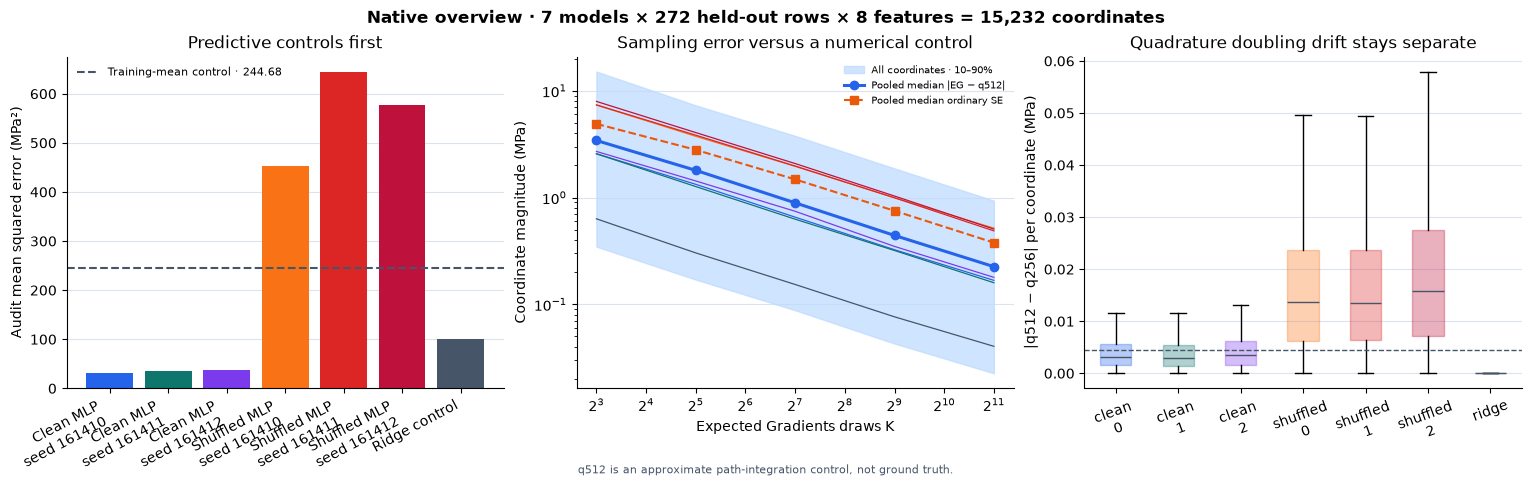

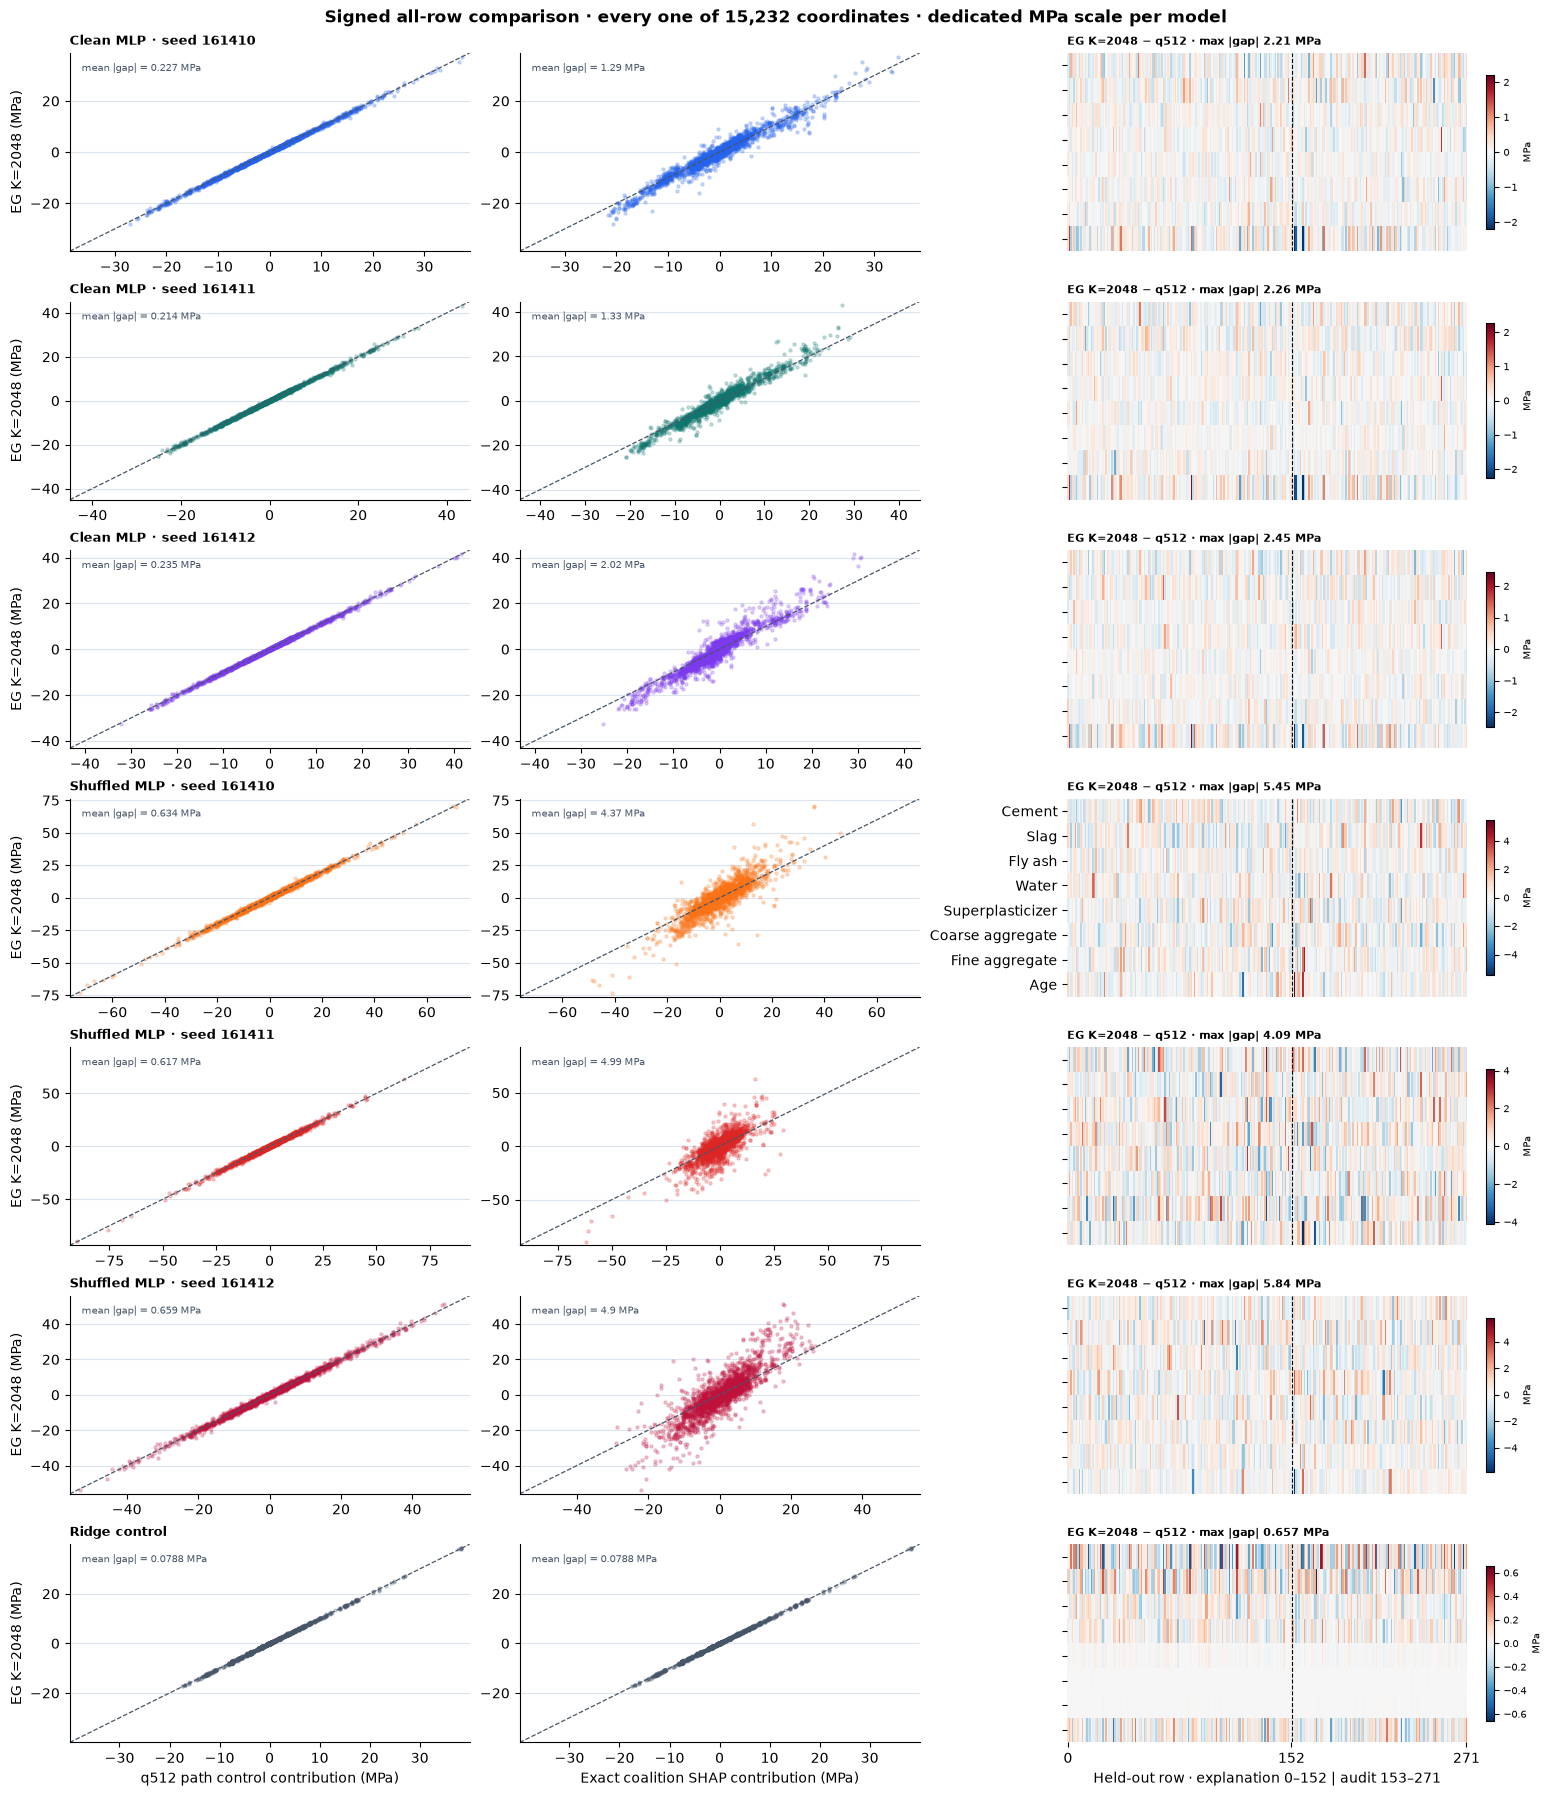

In [76]:
show_figure(
    plots.plot_native_overview(prepared, evaluated),
    "14_native_overview",
)
show_figure(
    plots.plot_allrow_method_map(evaluated),
    "15_allrow_method_map",
)


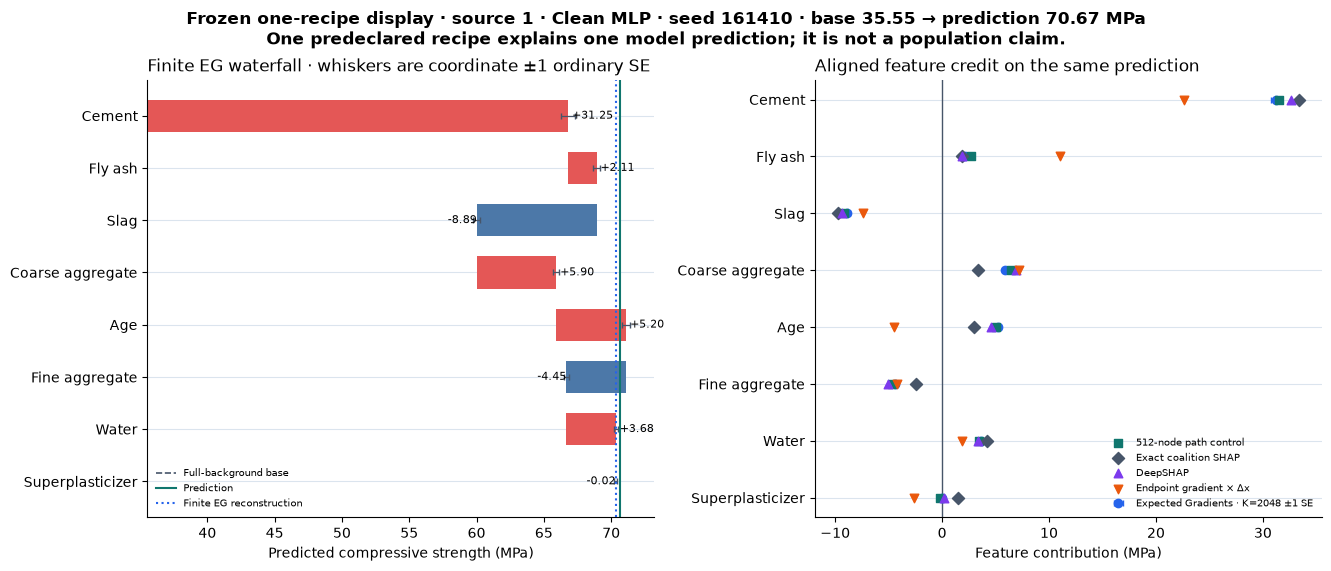

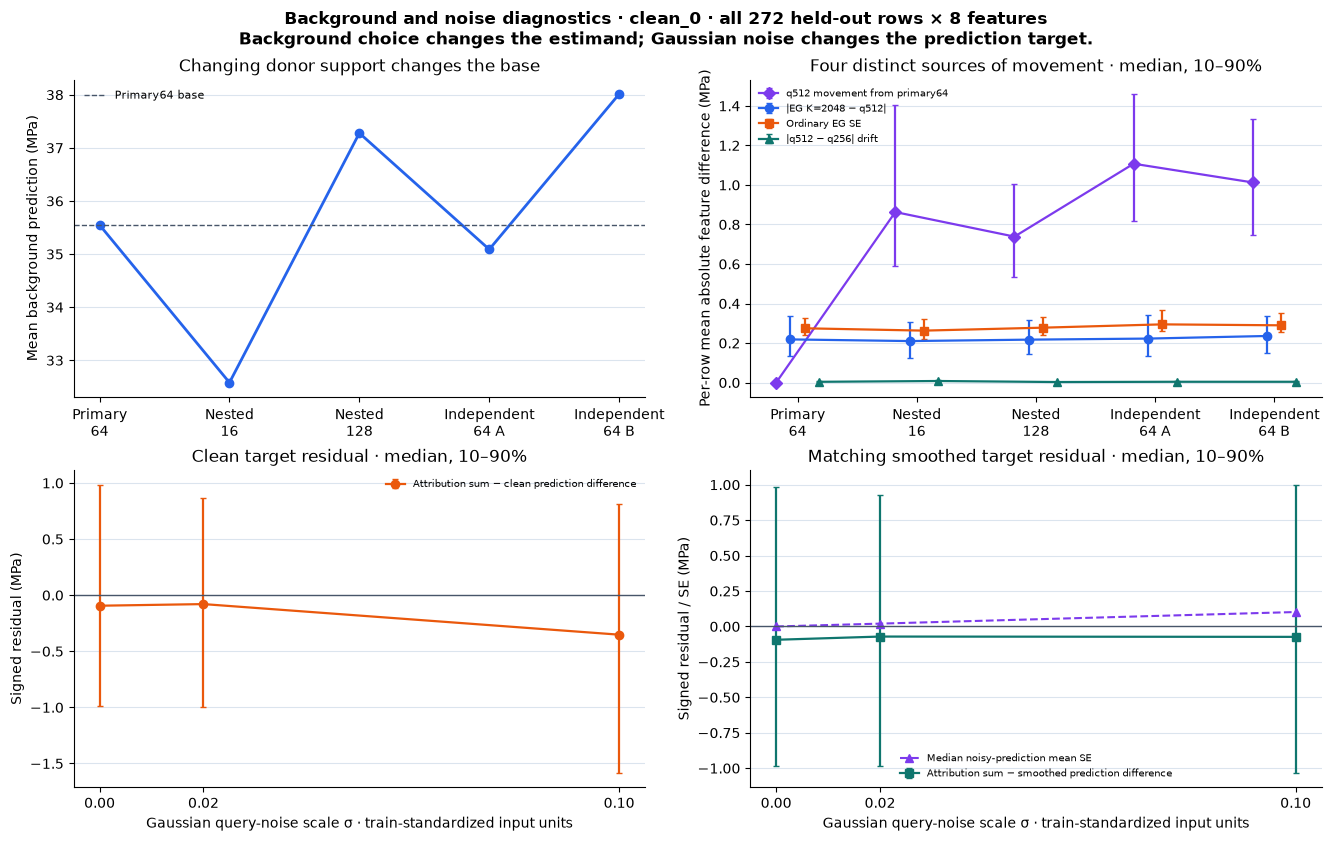

In [77]:
show_figure(
    plots.plot_fixed_waterfall(fixed_play, feature_names=FEATURE_NAMES),
    "16_fixed_waterfall",
)
show_figure(
    plots.plot_background_and_noise(evaluated),
    "17_background_and_noise",
)


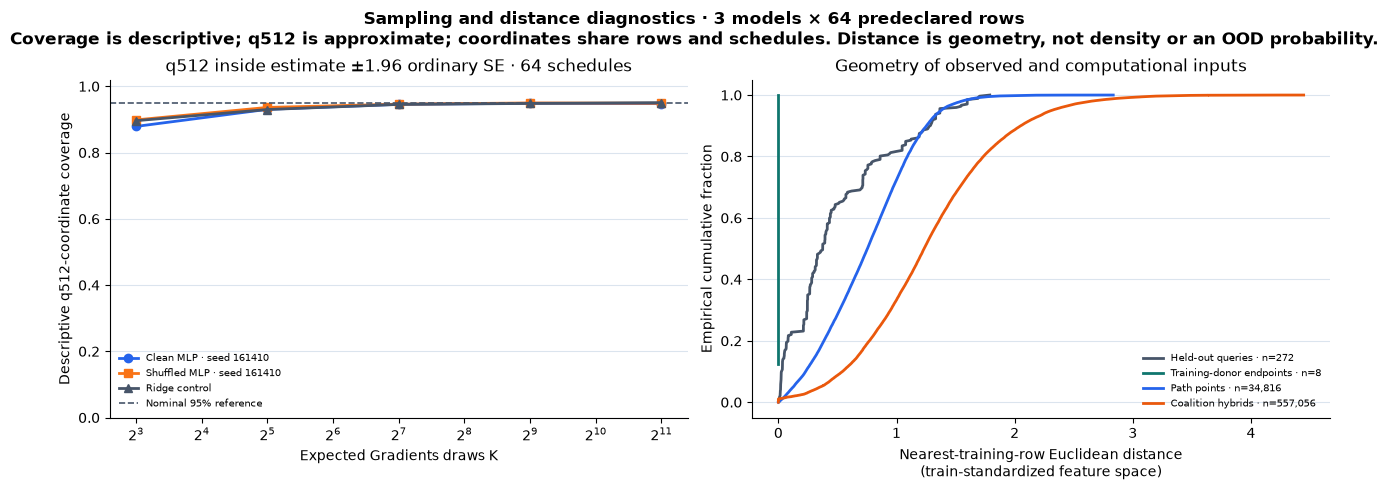

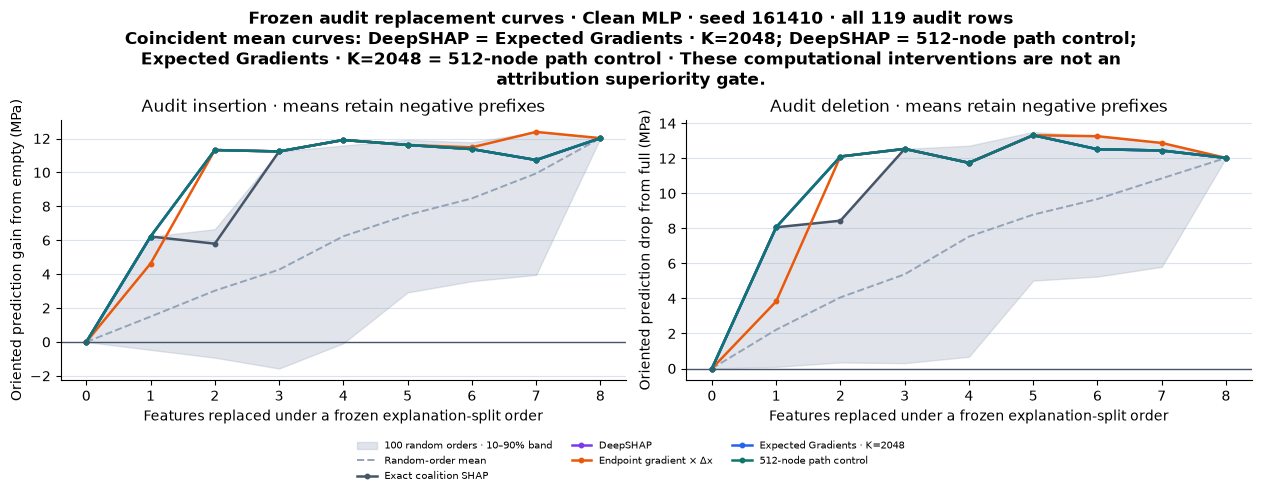

In [78]:
show_figure(
    plots.plot_replicates_and_distance(evaluated),
    "18_replicates_and_distance",
)
show_figure(
    plots.plot_replacement_curves(evaluated, model_key="clean_0"),
    "19_replacement_curves",
)


### Try It Yourself 2 — choose a recipe, background, budget, and noise scale

The canonical first run must use the first audit recipe, `clean_0`, the primary 64-row background,
K=2048, and sigma zero. After reproducing that fixed display, edit the model, any held-out source
row, one of the five background designs, a nested K budget, or a predeclared sigma. Recompute the
clean/noisy samples, quadrature control, exact feature game, and local replacement curves rather than
slicing cached arrays.


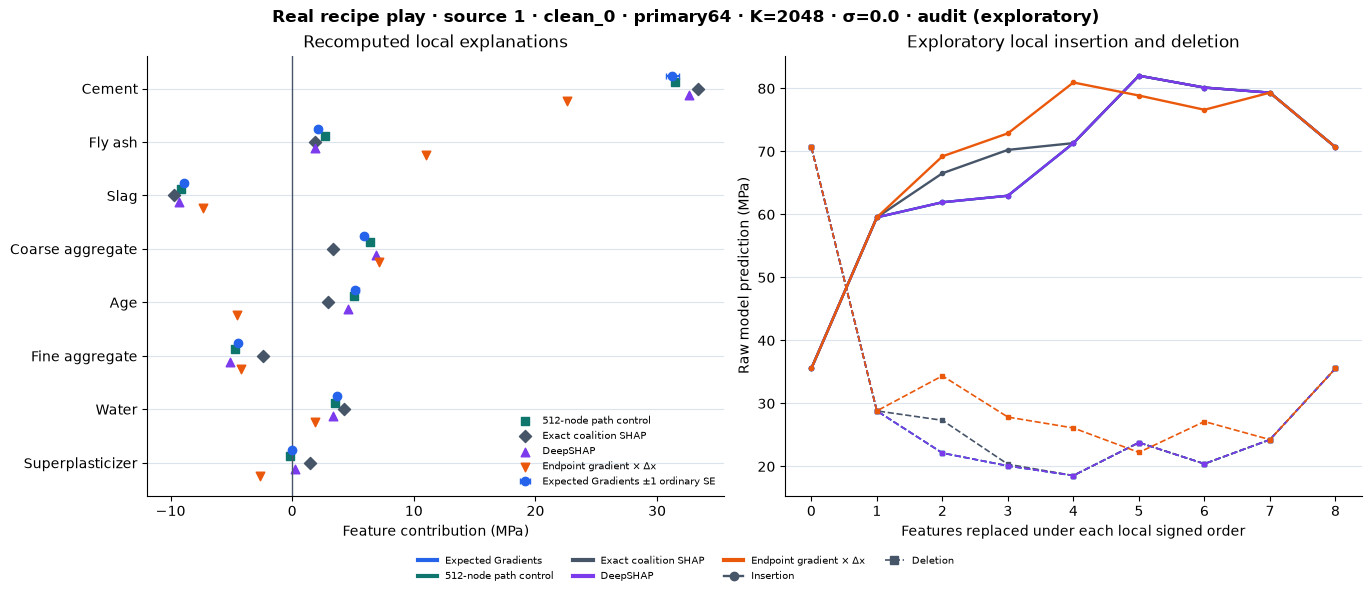

In [79]:
real_play = native_play(
    fitted,
    prepared,
    evaluated,
    train,
    explain,
    audit,
    methods=methods,
    deep_methods=deep_methods,
    model_key="clean_0",
    split="audit",
    row_index=0,
    background_key="primary64",
    samples=2048,
    sigma=0.0,
)
show_figure(
    plots.plot_real_recipe_play(real_play, feature_names=FEATURE_NAMES),
    "20_real_recipe_play",
)


<details><summary>Ideas to try</summary>

- Hold model and row fixed while moving from nested 16 to primary 64 to nested 128 donors.
- Compare sigma zero with `0.02` and `0.10`; read the clean and smoothed residuals separately.
- Find a row whose EG and exact global orders agree while their signed magnitudes differ.
- Compare K=32 and K=2048 on the same literal prefix, then inspect whether the ordinary SE predicted
  the observed change.
- Compare a clean and shuffled model on the same recipe before interpreting either explanation.

These choices occur after audit evaluation. They are exploratory diagnostics and cannot support a
new confirmatory audit claim.

</details>


## How to interpret the completed study

Read the eventual figures in this order:

1. Require clean predictors to beat the training-mean and shuffled-target controls before discussing
   attribution quality.
2. Validate the nine methods on analytic fixtures and require strict same-draw author parity. Keep
   that implementation check separate from convergence to the path target.
3. Compare nested Monte Carlo estimates with quadrature doubling and ordinary SE. A small SE with a
   large 256-to-512 change points to integration-control limits; a large SE is sampling instability.
4. Compare completeness residuals with signed coordinate differences. A path method may converge
   and be complete while disagreeing with exact feature-coalition Shapley.
5. Read background movement beside sampling error. Alternate empirical supports ask different
   questions; they are not replicate confidence intervals for one population target.
6. At nonzero noise, compare with the smoothed-query prediction. A clean-target discrepancy can be
   the intended target shift rather than failed local accuracy.
7. Read global audit replacement curves beside random orders and all-row variability. A favorable
   early prefix does not establish exact attribution or physical causality.

## Limitations and method scope

Expected Gradients uses straight paths and ordinary derivatives. Exact ReLU kinks require a
subgradient convention, finite Monte Carlo estimates have sampling error, and finite quadrature is
approximate for gradient jumps. Background choice is part of the estimand. Convex interpolation,
Gaussian perturbation, and feature-coalition replacement can create inputs far from observed
recipes.

The Concrete background is empirical and observational. Replacing cement, water, aggregate, or age
inside a predictor is a computational intervention on its input. It is not a randomized physical
experiment or evidence that the attribution is a causal effect in concrete production.

For classification, explaining a logit, probability, or loss would define different scalar
functions. This study avoids that ambiguity by explaining raw MPa. It does not add attribution-prior
training: changing the training objective would require a new pre-fit protocol, lambda selection,
performance guardrails, and repeated training evidence.

## Further research

- Compare independent schedule replicates with nominal `estimate ± 1.96 SE` coverage on a
  predeclared coordinate set without treating coordinates as independent experiments.
- Test antithetic or stratified alpha sampling as optional variance-reduction estimators, reporting
  measured variance instead of assuming improvement.
- Split ReLU paths analytically at known activation kinks and compare exact piecewise integration
  with Gauss-Legendre drift.
- Replace isotropic Gaussian noise with a declared domain-aware perturbation and derive its new
  smoothed target before measuring it.
- Add attribution-prior training only under a separately frozen study that retains predictive
  performance and repeated-seed controls.

## Reading

- Erion et al., [*Improving performance of deep learning models with axiomatic attribution priors
  and expected gradients*](https://arxiv.org/abs/1906.10670).
- Sundararajan, Taly and Yan,
  [*Axiomatic Attribution for Deep Networks*](https://proceedings.mlr.press/v70/sundararajan17a.html).
- Lundberg and Lee,
  [*A Unified Approach to Interpreting Model Predictions*](https://arxiv.org/abs/1705.07874).
- Official SHAP
  [`GradientExplainer` documentation](https://shap.readthedocs.io/en/stable/generated/shap.GradientExplainer.html).
- Official Captum
  [`GradientShap` documentation](https://captum.ai/api/gradient_shap.html).
